[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/04_Botnet_DGA_Detection/HybridQGNN_BotnetDetection_Sammartino2026.ipynb)

# Hybrid quantum graph neural network (DQTE) for IoT botnet detection: Sammartino (2026) step by step

**Paper.** V. Sammartino, *Hybrid Quantum Graph Neural Networks for Robust Botnet Detection in Modern IoT Ecosystems*,
Future Generation Computer Systems 185 (2026) 108650. DOI: [10.1016/j.future.2026.108650](https://doi.org/10.1016/j.future.2026.108650).

**What this notebook does.** It rebuilds the paper's **Direct Quantum Topological Embedding (DQTE)** pipeline on real
CIC-IoT-2023 flows:

1. take IoT flows (benign vs botnet = Mirai and DoS traffic), reduce them to **8 principal components** and scale to `[0, pi]`;
2. build a **k-nearest-neighbour similarity graph** (one node per flow, edges between flows with similar behaviour);
3. **pre-compute the graph aggregation** `X' = L X` with the renormalised Laplacian `L = D^-1/2 (A+I) D^-1/2` on the classical side;
4. feed `X'` into an **8-qubit variational quantum circuit** (angle embedding, 3 `BasicEntanglerLayers`, `<Z>` read-out) in
   parallel with a **classical linear skip path**, then BatchNorm, a linear classifier and log-softmax;
5. train with Adam and class-weighted NLL for 10 epochs in mini-batches of 128 nodes;
6. compare against the paper's classical baselines (MLP, GCN, GraphSAGE, GAT, XGBoost), redo the ablation (no topology,
   RBF-SVM, MLP, no skip), the gradient-at-initialisation table, the ROC/confusion figures and the latency measurement.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (default in the config cell) finishes in a few minutes;
set it to `False` for the full-size run (20,000 nodes, 5 seeds). The CIC-IoT-2023 table is downloaded from Hugging Face
(about 53 MB parquet, not gated; if you hit a gate or rate limit, add your own token as the Colab secret `HF_TOKEN`:
*key icon in the left bar -> Add new secret*). No token is written anywhere in this notebook.

**What you get at the end.** Dataset exploration plots, a drawing of the executed quantum circuit, DQTE and baseline
metrics (mean +/- std over seeds), the paper's Tables 1, 3, 4 and Figures 4 to 7 re-drawn from your own run, and a
claim-by-claim verdict.

## The paper in one page

* **Problem.** Peer-to-peer IoT botnets (Mirai, Mozi) hide in legitimate traffic. Classical GNNs over-smooth and treat flows
  independently if they are tabular; quantum graph networks that put the graph *inside* the circuit need circuits that grow
  with the graph.
* **Decision.** Per node (flow): botnet vs benign. Metric of record: **balanced accuracy** (plus F1, recall, AUC).
* **Method (DQTE).** (i) Standardise, PCA to `Q = 8` components, scale to `[0, pi]`. (ii) Directed unweighted **k-NN graph in the
  reduced feature space** (a *semantic behavioural topology*, not the physical network; the authors state this explicitly).
  (iii) `A_hat = A + I`, `D_hat_ii = sum_j A_hat_ij`, `L_hat = D_hat^-1/2 A_hat D_hat^-1/2`, `X' = L_hat X` computed once with sparse
  products. (iv) 8-qubit VQC: `RY(x'_j)` angle embedding, 3 layers of `BasicEntanglerLayers`, `<Z_j>` per qubit gives `h_q`;
  a parallel `Linear(8, 8)` skip gives `h_c`; `[h_q || h_c] -> BatchNorm -> Linear -> LogSoftmax`. (v) NLL loss with
  class-frequency weights `w_c = N / (C N_c)`, Adam, mini-batches of 128 nodes, 10 epochs, PennyLane `lightning.qubit`
  with **adjoint differentiation**, PyTorch.
* **Data.** CIC-IoT-2023, "specifically processed to isolate complex botnet scenarios including Mirai and various DoS
  topologies"; majority class (botnet) stratified-undersampled to about **4 : 1** (botnet : benign); 60/20/20 stratified split.
* **Claims.** Balanced accuracy 0.953 +/- 0.004, F1 0.951, recall 0.948, AUC 0.985 (Table 3, 100 runs); classical baselines
  0.812 to 0.908 balanced accuracy; ablation (Table 4): no topology 0.841, topology + RBF-SVM 0.921, topology + MLP 0.918,
  topology + VQC without skip 0.907; gradient magnitude at initialisation 0.0031 (no skip) vs 0.0412 (skip) (Table 1);
  FPR 5.60 %, FNR 2.97 % (Fig. 7); ROC AUC 0.985 / 0.941 / 0.884 for DQTE / GCN / MLP (Fig. 5); 4.1 ms inference latency
  per batch of 128 (Table 5); about 4x training speed-up from pre-computed aggregation.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | CIC-IoT-2023, "botnet scenarios incl. Mirai and DoS" | HF `lacg030175/CIC-IoT-2023` (subsampled public mirror of the same data, 39 flow features). **Scenario A (main): botnet = `Mirai` + `DoS` attack classes (7 sub-types), benign = `BenignTraffic`** (`# CHOICE`, the paper's wording). **Scenario B (sensitivity, fewer seeds): all 33 attack types count as botnet**, because scenario A turned out to be far easier than the paper's baseline numbers suggest |
| Nodes | flows | one node per flow; duplicates dropped; no IPs exist in the public tables |
| Graph | k-NN, Euclidean, reduced space, directed, unweighted; **k not given** | k = 10 in the `[0, pi]` PCA space (`# CHOICE`); built **separately inside the train, validation and test sets** so no node ever sees a node of another split (inductive; the paper's wording "nodes in the batch" does not say which) |
| Number of nodes | not stated; Fig. 7 counts imply about 3,950 test nodes | `N_NODES` = 20,000 in the full run (4,000 benign + 16,000 botnet), 3,000 in FAST mode |
| Class ratio | text: 4 : 1 botnet : benign; Fig. 7 counts (about 1,950 botnet vs 2,000 benign) imply about 1 : 1 | 4 : 1 as in the text. The two statements of the paper contradict each other |
| Preprocessing | standardise, PCA(8), scale to [0, pi] | exactly this, all fitted on the **training split only**, validation/test clipped to [0, pi] |
| Ansatz | `BasicEntanglerLayers`, 8 qubits, 3 layers; Fig. 2 calls the chain of CNOTs "adjacent" | `qml.BasicEntanglerLayers` (RX rotation, CNOT **ring** incl. the 7-to-0 closing gate, as PennyLane defines it), weights initialised U[0, 2 pi] (the `TorchLayer` default) |
| Parameter count | Table 2: 168 = 3L Q + Q^2 + 2Q | arithmetic does not match `BasicEntanglerLayers` (3 x 8 = **24** circuit parameters, not 72). Our count is printed below (162) |
| Skip path | linear `Q -> Q` | `nn.Linear(8, 8)` without activation |
| Optimiser | Adam, NLL, batch 128, 10 epochs; learning rate not stated | Adam, lr = 0.01 (`# CHOICE`), 10 epochs, batch 128 |
| Simulator | PennyLane `lightning.qubit`, adjoint | **Training uses an exact PyTorch state-vector implementation of the same circuit** (a 128-node training step takes seconds with `lightning.qubit` batched adjoint on a CPU, versus milliseconds here; the timing cell prints both); a cell **asserts** that it matches the PennyLane QNode (outputs and gradients) and the drawing/specs come from the PennyLane QNode |
| Baselines | MLP and GCN parameter-matched (168) and unconstrained, GraphSAGE, GAT (4 heads), XGBoost | all re-implemented in plain PyTorch / XGBoost (`torch_geometric` is not needed). Hidden sizes of the UC models are our choice (the paper's counts do not map to a stated architecture) |
| Seeds | 100 runs | `SEEDS` (3 in FAST, 5 in full; scenario B uses 2 / 3); each seed redraws the node sample, the split, PCA, graph and initialisation |
| Hardware | Xeon + H100 | CPU only |

In [1]:
# Installs pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn,
# matplotlib, scipy and PyTorch. A session restart may be requested after the install: if so, run all again.
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules

def _have(mod):
    try:
        importlib.import_module(mod)
        return True
    except Exception:
        return False

if IN_COLAB or not all(_have(m) for m in ["pennylane", "pennylane_lightning", "xgboost", "pyarrow", "huggingface_hub"]):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install",
                    "pennylane==0.45.1", "pennylane-lightning==0.45.0", "xgboost==3.4.1",
                    "pyarrow", "huggingface_hub"], check=False)

In [2]:
# ------------------------------------------------------------------ configuration (every tunable constant)
FAST_MODE = False           # True: class-demo size (a few minutes). False: paper-size run (20,000 nodes, 5 seeds)
SEED = 42                   # master seed (also the seed used for all single-run plots)

# --- data
HF_REPO = "lacg030175/CIC-IoT-2023"          # public mirror of CIC-IoT-2023 (39 features, 34 labels)
HF_FILE = "random/train-00000-of-00001.parquet"
DATA_DIR = "ciciot2023_cache"                # downloaded files are cached here (never committed)
DATA_PATH = ""                               # optional: path of an uploaded parquet/CSV with the same columns
BOTNET_CLASSES = ["Mirai", "DoS"]            # CHOICE (scenario A, main): 'attack_class' values treated as botnet traffic
RUN_ALL_ATTACKS = True                       # scenario B (sensitivity): every attack group counts as "botnet" (harder task)
N_NODES = 3000 if FAST_MODE else 20000       # graph nodes (flows) per run; Fig. 7 of the paper implies ~19,800
BOTNET_TO_BENIGN = 4                         # paper text: ~4:1 (botnet:benign)
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.6, 0.2, 0.2   # paper: 60/20/20 stratified

# --- preprocessing / graph
N_QUBITS = 8                                 # = number of PCA components (paper)
K_NEIGHBOURS = 10                            # CHOICE: k of the k-NN graph (not given in the paper)

# --- hybrid quantum model (paper)
N_LAYERS = 3                                 # BasicEntanglerLayers depth
EPOCHS = 10                                  # paper: 10 epochs
BATCH_SIZE = 128                             # paper: 128 nodes per mini-batch
LR = 0.01                                    # CHOICE: Adam learning rate (not given)

# --- classical baselines
MLP_EPOCHS = 30                              # CHOICE
GNN_EPOCHS = 40 if FAST_MODE else 100       # CHOICE: full-batch GCN/SAGE/GAT epochs
GNN_LR, GNN_WD = 0.01, 5e-4

# --- repeated runs
SEEDS = [42, 43, 44] if FAST_MODE else list(range(42, 47))
SEEDS_B = SEEDS[:2] if FAST_MODE else SEEDS[:3]   # seeds for the all-attacks sensitivity scenario
GRAD_SEEDS = 30 if FAST_MODE else 100        # paper: 100 seeds for Table 1
EQUIV_BATCH = 16                             # batch used to assert simulator equivalence
IBM_TOKEN = ""                               # unused (no real-hardware cell in this paper); kept for template consistency
print("FAST_MODE =", FAST_MODE, "| N_NODES =", N_NODES, "| seeds =", SEEDS)

FAST_MODE = False | N_NODES = 20000 | seeds = [42, 43, 44, 45, 46]


In [3]:
import os, time, math, json, warnings, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import scipy, scipy.sparse as sp
import sklearn, xgboost
import pennylane as qml
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score, precision_score,
                             roc_auc_score, confusion_matrix, roc_curve)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

torch.set_num_threads(min(4, os.cpu_count() or 1))
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| xgboost", xgboost.__version__)

# Hugging Face token: only needed if the dataset is gated or you are rate limited. Never typed into the notebook.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: key icon > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("HF token available:", HF_TOKEN is not None)

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | xgboost 3.4.1
HF token available: True


## 1. Data: CIC-IoT-2023 flows, botnet vs benign

CIC-IoT-2023 (Neto et al., Sensors 2023) records 33 attacks against a 105-device IoT lab. The public parquet mirror used here
holds 1.07 M flow records with 39 numeric flow features and three label columns (`Label` = 34 fine labels, `attack_class` =
8 groups, `label` = 0/1). The paper keeps "Mirai and various DoS topologies" as botnet traffic; we take the `Mirai`
(greeth flood, greip flood, udpplain) and `DoS` (HTTP, SYN, TCP, UDP flood) groups as the botnet class and
`BenignTraffic` as benign.

*Cleaning* (same recipe as the other notebooks of this series): numeric coercion, drop +/-inf and NaN, drop exact duplicate
rows, drop constant columns. The node sample of each run is then drawn with a **stratified undersampling of the botnet class
to 4 : 1**, stratified over the 7 botnet sub-types so no family dominates.

In [4]:
from huggingface_hub import hf_hub_download

def load_raw_table():
    # Returns the raw table (all 34 labels) from DATA_PATH, or downloads the HF parquet into DATA_DIR.
    if DATA_PATH:
        p = DATA_PATH
    else:
        p = os.path.join(DATA_DIR, HF_FILE)
        if not os.path.exists(p):
            p = hf_hub_download(repo_id=HF_REPO, filename=HF_FILE, repo_type="dataset",
                                local_dir=DATA_DIR, token=HF_TOKEN or None)
    return pd.read_parquet(p) if str(p).endswith(".parquet") else pd.read_csv(p)

t0 = time.time()
raw = load_raw_table()
LABEL_COL, GROUP_COL = "Label", "attack_class"
FEATURES = [c for c in raw.columns if c not in (LABEL_COL, GROUP_COL, "label")]
print("download/load: %.1f s" % (time.time() - t0), "| raw table shape:", raw.shape)

# ---- cleaning on the botnet/benign subset
n0 = len(raw)
pool_all = raw.copy()
pool_all[FEATURES] = pool_all[FEATURES].apply(pd.to_numeric, errors="coerce")
pool_all = pool_all.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURES)
pool_all = pool_all.drop_duplicates(subset=FEATURES + [LABEL_COL])
const = [c for c in FEATURES if pool_all[c].nunique() <= 1]
pool_all = pool_all.drop(columns=const)
FEATURES = [c for c in FEATURES if c not in const]
pool_all["is_botnet"] = (pool_all[GROUP_COL] != "Benign").astype(int)
pool_all = pool_all.reset_index(drop=True)
print(f"full table: {n0:,} rows -> {len(pool_all):,} after cleaning; constant columns dropped: {const}")

# scenario A (main, the paper's text): botnet = Mirai + DoS ; scenario B (sensitivity): botnet = every attack group
pool = pool_all[pool_all[GROUP_COL].isin(["Benign"] + BOTNET_CLASSES)].reset_index(drop=True)
pool_B = pool_all
print(f"scenario A (Mirai + DoS vs benign): {len(pool):,} flows | scenario B (all attacks vs benign): {len(pool_B):,} flows")
print(pool[LABEL_COL].value_counts().to_string())

download/load: 0.7 s | raw table shape: (1073851, 42)


full table: 1,073,851 rows -> 989,481 after cleaning; constant columns dropped: []


scenario A (Mirai + DoS vs benign): 416,938 flows | scenario B (all attacks vs benign): 989,481 flows
Label
BenignTraffic         159474
DoS-HTTP_Flood         39930
Mirai-greip_flood      39837
Mirai-greeth_flood     39832
Mirai-udpplain         39758
DoS-SYN_Flood          38122
DoS-UDP_Flood          33403
DoS-TCP_Flood          26582


## 2. Splits, PCA to 8 components, scaling to [0, pi], the k-NN graph and the DQTE aggregation

`prepare(seed)` runs the *whole* classical front end of Fig. 1 (stage 1) for one seed:
sample nodes -> stratified 60/20/20 split -> `StandardScaler` -> `PCA(8)` -> `MinMaxScaler(0, pi)`
(all **fitted on the training split only**) -> k-NN graph **inside each split** -> `A_hat = A + I` ->
`L_hat = D^-1/2 A_hat D^-1/2` -> `X' = L_hat X`.

Because every node has exactly `k` in-neighbours plus itself, `D_hat_ii = k + 1` for all `i` and `L_hat = A_hat / (k + 1)`,
i.e. the Laplacian propagation is a *neighbourhood mean*; the code keeps the general formula and asserts the row sums.

In [5]:
def sample_nodes(seed, pool):
    # Stratified undersampling of botnet (over its sub-types, at least 5 flows each) to BOTNET_TO_BENIGN : 1; random benign sample.
    g = np.random.default_rng(seed)
    n_ben = int(round(N_NODES / (BOTNET_TO_BENIGN + 1)))
    n_bot = N_NODES - n_ben
    ben = pool[pool.is_botnet == 0]
    bot = pool[pool.is_botnet == 1]
    ben_s = ben.iloc[g.choice(len(ben), n_ben, replace=False)]
    frac = n_bot / len(bot)
    parts = [d.iloc[g.choice(len(d), min(len(d), max(5, int(round(len(d) * frac)))), replace=False)] for _, d in bot.groupby(LABEL_COL)]
    return pd.concat([ben_s] + parts).sample(frac=1.0, random_state=seed).reset_index(drop=True)

def knn_propagation(X, k):
    # Directed unweighted kNN graph: edge (j -> i) if j is among the k nearest neighbours of i (self excluded).
    # Returns L_hat = D^-1/2 (A+I) D^-1/2 as scipy CSR, the neighbour-mean matrix M (A/k) and the neighbour index table.
    n = len(X)
    idx = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)
    keep = idx != np.arange(n)[:, None]
    keep[keep.all(1), -1] = False                      # self not returned (duplicate points): drop the farthest one
    nbr = idx[keep].reshape(n, k)
    rows = np.repeat(np.arange(n), k)
    A = sp.csr_matrix((np.ones(n * k, dtype=np.float32), (rows, nbr.ravel())), shape=(n, n))
    A_hat = A + sp.identity(n, dtype=np.float32, format="csr")
    d = np.asarray(A_hat.sum(1)).ravel()               # D_hat_ii = sum_j A_hat_ij
    Dm = sp.diags(d ** -0.5)
    L_hat = (Dm @ A_hat @ Dm).tocsr().astype(np.float32)
    M = (A / k).tocsr().astype(np.float32)
    return L_hat, M, nbr

def to_torch_sparse(m):
    m = m.tocoo()
    return torch.sparse_coo_tensor(torch.as_tensor(np.vstack([m.row, m.col]), dtype=torch.long), torch.as_tensor(m.data), m.shape).coalesce()

def prepare(seed, pool=pool):
    df = sample_nodes(seed, pool)
    y = df["is_botnet"].values
    idx = np.arange(len(df))
    tr, rest = train_test_split(idx, test_size=VAL_FRAC + TEST_FRAC, stratify=df[GROUP_COL], random_state=seed)
    va, te = train_test_split(rest, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=df.loc[rest, GROUP_COL], random_state=seed)
    F_all = df[FEATURES].values.astype(np.float64)
    sc = StandardScaler().fit(F_all[tr])                                        # fit on train only
    pca = PCA(n_components=N_QUBITS, random_state=seed).fit(sc.transform(F_all[tr]))
    Z = {s: pca.transform(sc.transform(F_all[i])) for s, i in zip(["tr", "va", "te"], [tr, va, te])}
    mm = MinMaxScaler((0, np.pi)).fit(Z["tr"])
    X = {s: np.clip(mm.transform(Z[s]), 0, np.pi).astype(np.float32) for s in Z}  # angles in [0, pi]
    D = dict(seed=seed, df=df, idx=dict(tr=tr, va=va, te=te), pca=pca, Z=Z, X=X,
             raw={s: F_all[i] for s, i in zip(["tr", "va", "te"], [tr, va, te])},
             y={s: y[i] for s, i in zip(["tr", "va", "te"], [tr, va, te])},
             lab={s: df.loc[i, LABEL_COL].to_numpy(dtype=object) for s, i in zip(["tr", "va", "te"], [tr, va, te])},
             grp={s: df.loc[i, GROUP_COL].to_numpy(dtype=object) for s, i in zip(["tr", "va", "te"], [tr, va, te])},
             L={}, M={}, nbr={}, Xp={})
    for s in X:
        L, M, nbr = knn_propagation(X[s], K_NEIGHBOURS)
        assert np.allclose(np.asarray(L.sum(1)).ravel(), 1.0, atol=1e-4), "directed kNN + self loop gives a row-stochastic L_hat"
        D["L"][s], D["M"][s], D["nbr"][s] = L, M, nbr
        D["Xp"][s] = (L @ X[s]).astype(np.float32)                              # X' = L_hat X  (Eq. 2)
    return D

t0 = time.time()
DATA = prepare(SEED)
print("prepared seed %d in %.1f s" % (SEED, time.time() - t0))
print({s: (DATA["X"][s].shape, int(DATA["y"][s].sum()), int((1 - DATA["y"][s]).sum())) for s in ["tr", "va", "te"]},
      "(shape, #botnet, #benign)")
print("explained variance of the 8 PCA components: %.3f" % DATA["pca"].explained_variance_ratio_.sum())

prepared seed 42 in 2.9 s
{'tr': ((12000, 8), 9600, 2400), 'va': ((4000, 8), 3200, 800), 'te': ((4000, 8), 3200, 800)} (shape, #botnet, #benign)
explained variance of the 8 PCA components: 0.666


## Dataset Exploration and Visualisation

Everything below uses the **real CIC-IoT-2023 flows** of the single run with `SEED`. The first block shows the raw table,
the original label values and the class counts; then the class distribution; then 2-D scatter plots in which every point is a
real flow coloured by its **ground-truth fine label** (benign, three Mirai families, four DoS families): first the raw PCA
coordinates fitted on the training split, then the same two coordinates scaled to `[0, pi]` (the quantum angles), then the
two angles after the DQTE aggregation `X' = L_hat X`; finally the k-NN graph drawn on a small random subset of training flows.

In [6]:
print("raw table shape:", raw.shape)
print("feature names (%d after cleaning):" % len(FEATURES)); print(FEATURES)
print("\noriginal label values (Label, 34 fine labels) and counts in the full public table:")
print(raw[LABEL_COL].value_counts().to_string())
print("\ngroup labels (attack_class):", raw[GROUP_COL].value_counts().to_dict())
print("binary label column:", raw["label"].value_counts().to_dict(), "(0 = benign, 1 = attack)")
print("\nsubset used here: shape %s; botnet classes = %s" % (pool.shape, BOTNET_CLASSES))
print("sampled nodes of this run, by fine label:"); print(DATA["df"][LABEL_COL].value_counts().to_string())

raw table shape: (1073851, 42)
feature names (39 after cleaning):
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance']

original label values (Label, 34 fine labels) and counts in the full public table:
Label
BenignTraffic              159990
DDoS-UDP_Flood              40192
DoS-HTTP_Flood              40071
Mirai-greeth_flood          40058
Recon-HostDiscovery         40038
DoS-TCP_Flood               40035
DDoS-ICMP_Fragmentation     40030
MITM-ArpSpoofing            40029
Recon-PortScan              40028
VulnerabilityScan           40019
DNS_Spoofing                40014
DDoS-SynonymousIP_Flood     400

binary label column:

 {1: 913861, 0: 159990} (0 = benign, 1 = attack)

subset used here: shape (416938, 43); botnet classes = ['Mirai', 'DoS']
sampled nodes of this run, by fine label:
Label
BenignTraffic         4000
DoS-HTTP_Flood        2481
Mirai-greip_flood     2476
Mirai-greeth_flood    2475
Mirai-udpplain        2471
DoS-SYN_Flood         2369
DoS-UDP_Flood         2076
DoS-TCP_Flood         1652


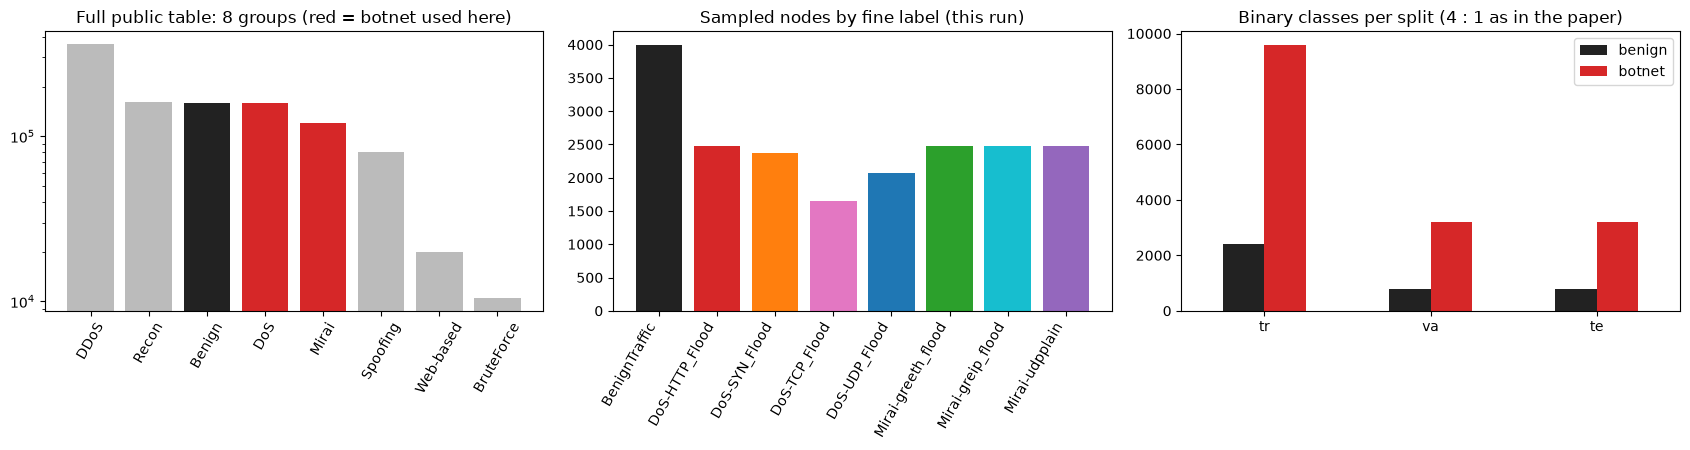

In [7]:
fine_labels = sorted(DATA["df"][LABEL_COL].unique(), key=lambda s: (s != "BenignTraffic", s))
palette = dict(zip(fine_labels, ["#222222", "#d62728", "#ff7f0e", "#e377c2", "#1f77b4", "#2ca02c", "#17becf", "#9467bd"]))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
vc = raw[GROUP_COL].value_counts()
ax[0].bar(vc.index, vc.values, color=["#222222" if i == "Benign" else ("#d62728" if i in BOTNET_CLASSES else "#bbbbbb") for i in vc.index])
ax[0].set_yscale("log"); ax[0].set_title("Full public table: 8 groups (red = botnet used here)"); ax[0].tick_params(axis="x", rotation=60)
vc2 = DATA["df"][LABEL_COL].value_counts().reindex(fine_labels)
ax[1].bar(range(len(vc2)), vc2.values, color=[palette[l] for l in vc2.index]); ax[1].set_xticks(range(len(vc2)))
ax[1].set_xticklabels(vc2.index, rotation=60, ha="right"); ax[1].set_title("Sampled nodes by fine label (this run)")
bin_counts = pd.DataFrame({s: np.bincount(DATA["y"][s], minlength=2) for s in ["tr", "va", "te"]}, index=["benign", "botnet"])
bin_counts.T.plot.bar(ax=ax[2], color=["#222222", "#d62728"]); ax[2].set_title("Binary classes per split (4 : 1 as in the paper)"); ax[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

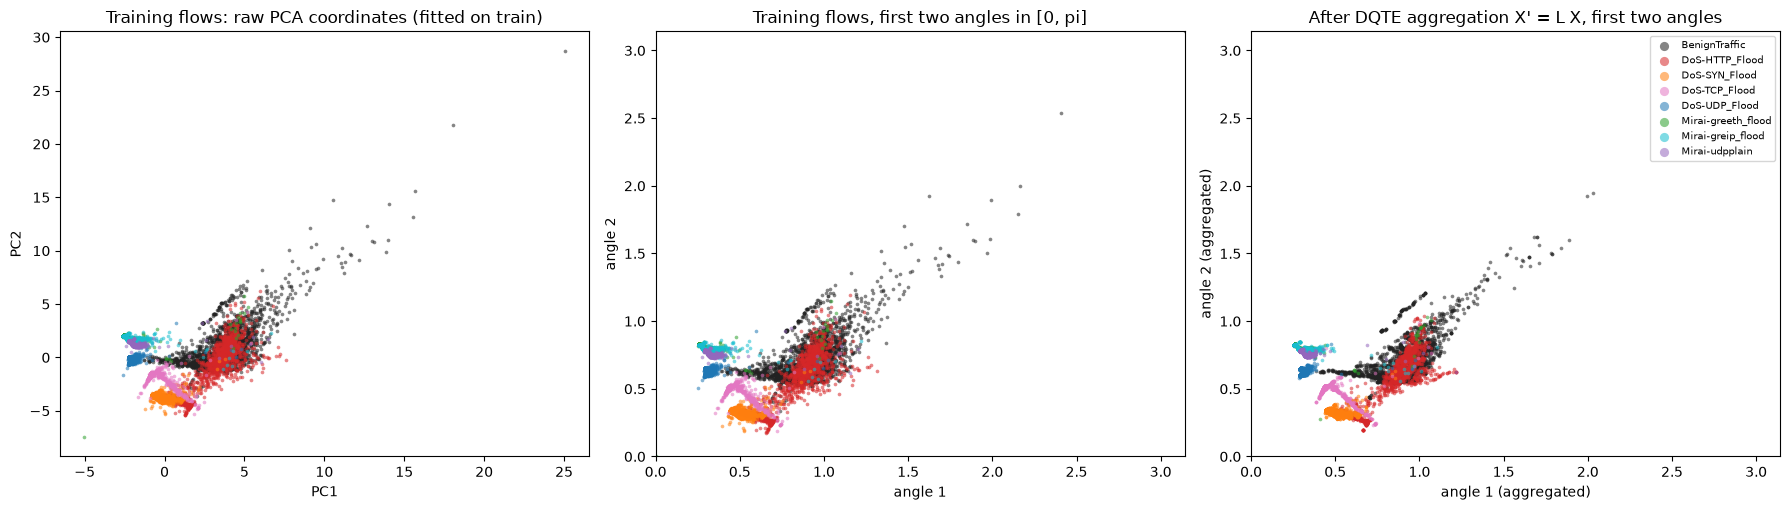

PC1/PC2 explain 17.9 % / 12.5 % of the variance


In [8]:
def scatter(ax, P, labs, title, xl, yl, lim=None):
    for l in fine_labels:
        m = labs == l
        ax.scatter(P[m, 0], P[m, 1], s=7, alpha=0.55, color=palette[l], label=l, linewidths=0)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl)
    if lim: ax.set_xlim(lim); ax.set_ylim(lim)

fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
scatter(ax[0], DATA["Z"]["tr"], DATA["lab"]["tr"], "Training flows: raw PCA coordinates (fitted on train)", "PC1", "PC2")
scatter(ax[1], DATA["X"]["tr"], DATA["lab"]["tr"], "Training flows, first two angles in [0, pi]", "angle 1", "angle 2", (0, np.pi))
scatter(ax[2], DATA["Xp"]["tr"], DATA["lab"]["tr"], "After DQTE aggregation X' = L X, first two angles", "angle 1 (aggregated)", "angle 2 (aggregated)", (0, np.pi))
ax[2].legend(fontsize=7, markerscale=2.5, loc="best")
plt.tight_layout(); plt.show()
print("PC1/PC2 explain %.1f %% / %.1f %% of the variance" % tuple(100 * DATA["pca"].explained_variance_ratio_[:2]))

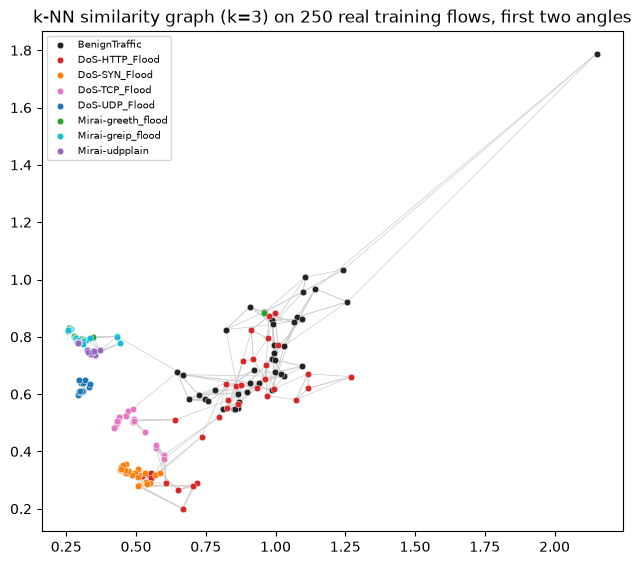

tr: 12000 nodes, 120000 directed edges (k=10); edge homophily binary = 0.996, fine label = 0.949
va: 4000 nodes, 40000 directed edges (k=10); edge homophily binary = 0.996, fine label = 0.930
te: 4000 nodes, 40000 directed edges (k=10); edge homophily binary = 0.995, fine label = 0.931


In [9]:
# The similarity graph itself: k-NN edges among a random subset of 250 real training flows (full graph has k edges per node).
g = np.random.default_rng(SEED)
sub = g.choice(len(DATA["X"]["tr"]), 250, replace=False)
Xs, labs_s = DATA["X"]["tr"][sub], DATA["lab"]["tr"][sub]
nb = NearestNeighbors(n_neighbors=4).fit(Xs).kneighbors(Xs, return_distance=False)[:, 1:]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for i in range(len(Xs)):
    for j in nb[i]:
        ax.plot([Xs[i, 0], Xs[j, 0]], [Xs[i, 1], Xs[j, 1]], color="#cccccc", lw=0.5, zorder=1)
for l in fine_labels:
    m = labs_s == l
    ax.scatter(Xs[m, 0], Xs[m, 1], s=22, color=palette[l], label=l, zorder=2, edgecolor="white", linewidths=0.3)
ax.set_title("k-NN similarity graph (k=3) on 250 real training flows, first two angles"); ax.legend(fontsize=7)
plt.show()
for s in ["tr", "va", "te"]:
    nbr, yy, ll = DATA["nbr"][s], DATA["y"][s], DATA["lab"][s]
    same_bin = (yy[nbr] == yy[:, None]).mean(); same_fine = (ll[nbr] == ll[:, None]).mean()
    print(f"{s}: {len(yy)} nodes, {nbr.size} directed edges (k={K_NEIGHBOURS}); edge homophily binary = {same_bin:.3f}, fine label = {same_fine:.3f}")

scenario B nodes by group: {'DDoS': 5881, 'Benign': 4000, 'Recon': 3093, 'DoS': 2661, 'Mirai': 2302, 'Spoofing': 1481, 'Web-based': 381, 'BruteForce': 202}


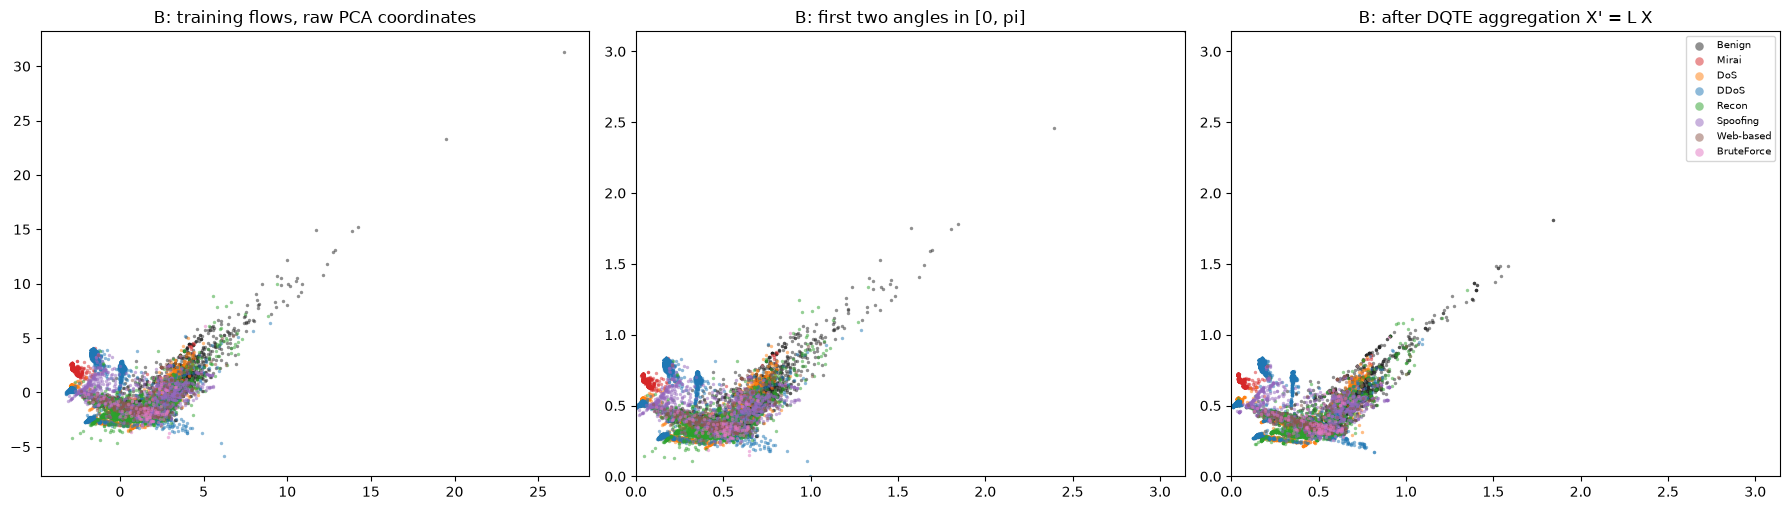

scenario B train graph: edge homophily binary = 0.835, attack group = 0.699


In [10]:
# Scenario B (sensitivity): ALL attack groups count as "botnet". Same pipeline, same figures, coloured by the 8 attack groups.
if RUN_ALL_ATTACKS:
    DATA_B = prepare(SEED, pool_B)
    groups = ["Benign", "Mirai", "DoS", "DDoS", "Recon", "Spoofing", "Web-based", "BruteForce"]
    gpal = dict(zip(groups, ["#222222", "#d62728", "#ff7f0e", "#1f77b4", "#2ca02c", "#9467bd", "#8c564b", "#e377c2"]))
    print("scenario B nodes by group:", {k: int(v) for k, v in DATA_B["df"][GROUP_COL].value_counts().items()})
    fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
    for a, P, ttl, lim in [(ax[0], DATA_B["Z"]["tr"], "B: training flows, raw PCA coordinates", None),
                           (ax[1], DATA_B["X"]["tr"], "B: first two angles in [0, pi]", (0, np.pi)),
                           (ax[2], DATA_B["Xp"]["tr"], "B: after DQTE aggregation X' = L X", (0, np.pi))]:
        for gname in groups:
            m = DATA_B["grp"]["tr"] == gname
            a.scatter(P[m, 0], P[m, 1], s=6, alpha=0.5, color=gpal[gname], label=gname, linewidths=0)
        a.set_title(ttl)
        if lim: a.set_xlim(lim); a.set_ylim(lim)
    ax[2].legend(fontsize=7, markerscale=2.5)
    plt.tight_layout(); plt.show()
    nb_ = DATA_B["nbr"]["tr"]; yb_, gb_ = DATA_B["y"]["tr"], DATA_B["grp"]["tr"]
    print(f"scenario B train graph: edge homophily binary = {(yb_[nb_] == yb_[:, None]).mean():.3f}, attack group = {(gb_[nb_] == gb_[:, None]).mean():.3f}")

## Quantum Circuit Architecture

The quantum core of DQTE is one 8-qubit circuit used as a node-wise feature transformer:

* **Encoding:** `AngleEmbedding(x', rotation="Y")`, i.e. `RY(x'_j)` on qubit `j` (paper Sec. 3.4, Fig. 2);
* **Variational part:** 3 layers of `qml.BasicEntanglerLayers` = one trainable `RX(theta_{l,j})` per qubit and a CNOT chain between
  neighbouring qubits (PennyLane closes the chain into a ring, CNOT 7 -> 0);
* **Measurement:** `<Z_j>` for each of the 8 qubits, giving `h_q` in `R^8`.

Assumptions where the paper is silent: rotation axis of the trainable gate (PennyLane default `RX`), ring closure, weight
initialisation U[0, 2 pi]. The drawing below is made from the **actual PennyLane QNode** (`lightning.qubit`, adjoint
differentiation, as in the paper), decomposed to the gates the device executes. Because a 128-node step on that device is
slow on a laptop CPU, training uses `quantum_core_torch`, an exact batched state-vector implementation of the same circuit,
and the cell after the drawing **asserts** that both give identical outputs and gradients.

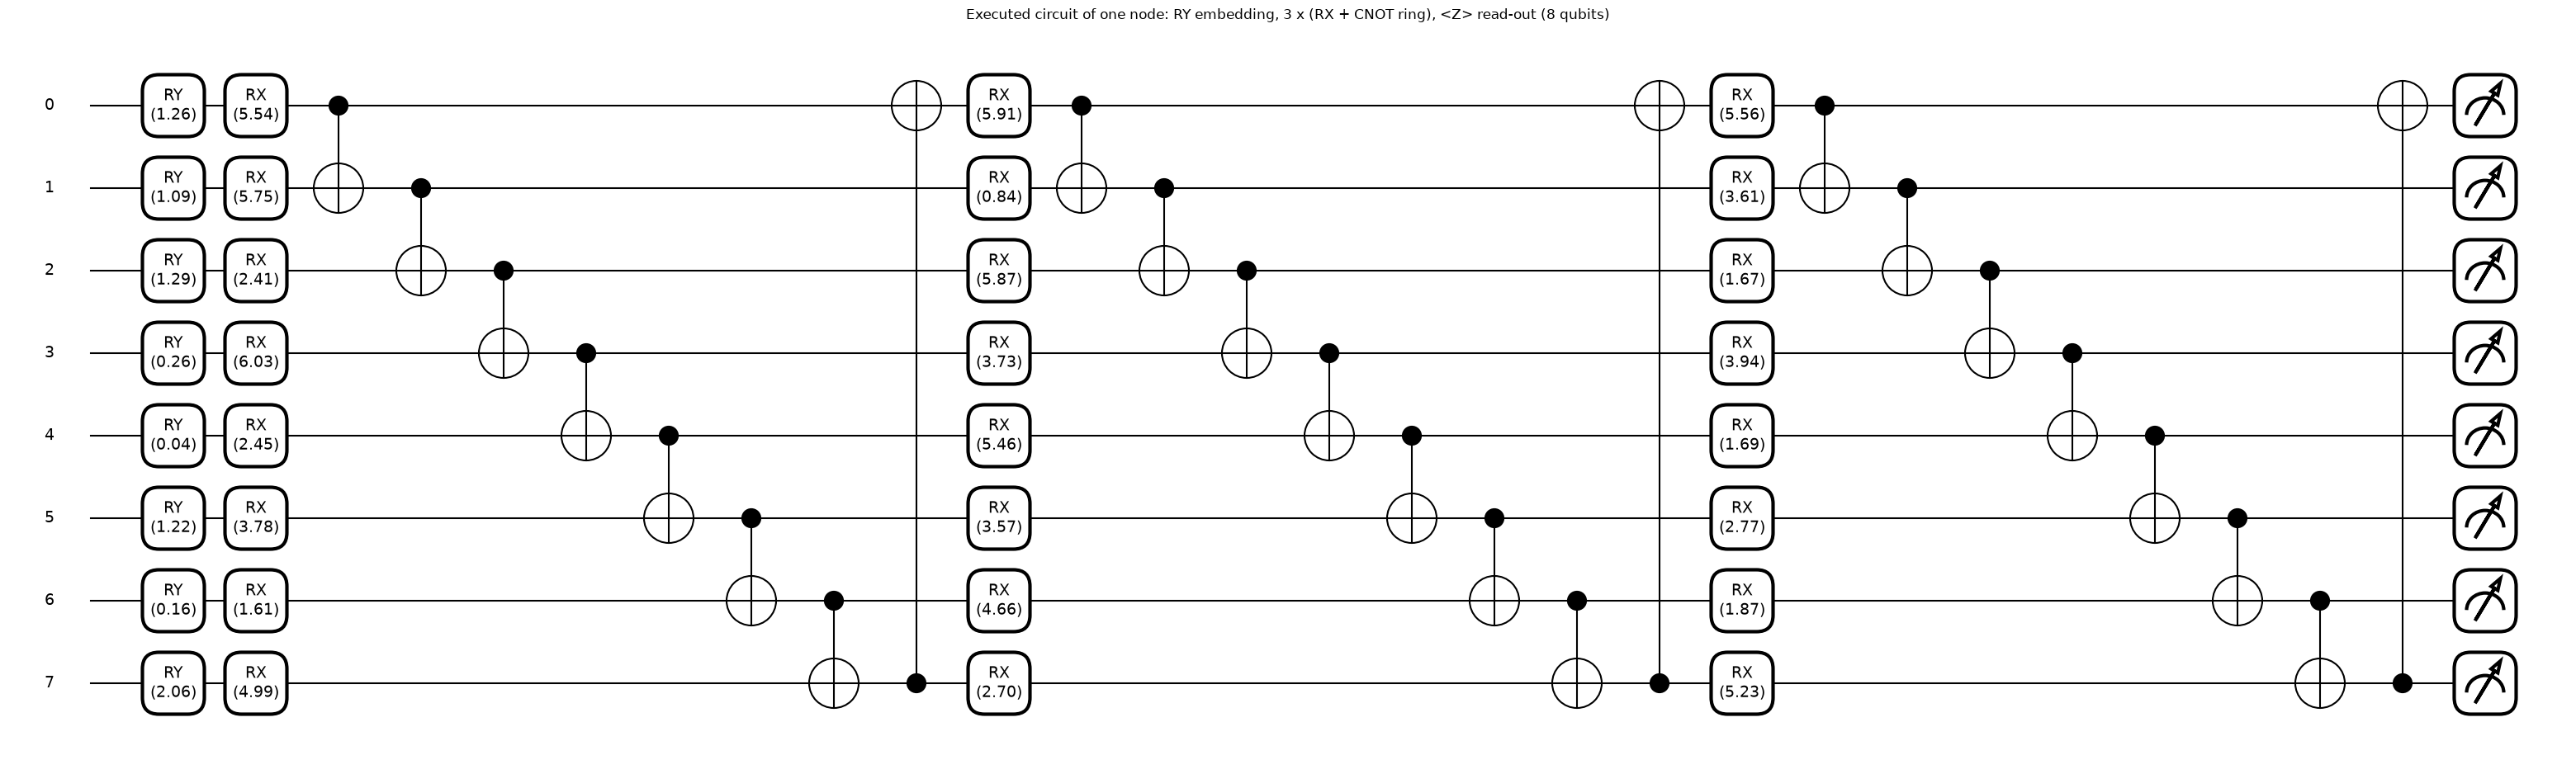

qubits: 8 | circuit depth (device level): 28 | gates: {'RY': 8, 'RX': 24, 'CNOT': 24} | trainable circuit parameters: 24 (3 layers x 8 qubits; inputs x' are not trainable)


In [11]:
dev_pl = qml.device("lightning.qubit", wires=N_QUBITS)

@qml.qnode(dev_pl, interface="torch", diff_method="adjoint")
def qnode(x, weights):
    qml.AngleEmbedding(x, wires=range(N_QUBITS), rotation="Y")
    qml.BasicEntanglerLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(j)) for j in range(N_QUBITS)]

x_demo = torch.tensor(DATA["Xp"]["tr"][0])
w_demo = (torch.rand(N_LAYERS, N_QUBITS) * 2 * np.pi).requires_grad_(True)
fig, ax = qml.draw_mpl(qnode, level="device", decimals=2)(x_demo, w_demo)
fig.suptitle("Executed circuit of one node: RY embedding, 3 x (RX + CNOT ring), <Z> read-out (8 qubits)", y=1.02)
plt.show()

specs = qml.specs(qnode, level="device")(x_demo, w_demo)
n_train_params = int(w_demo.numel())
print("qubits:", N_QUBITS, "| circuit depth (device level):", specs.resources.depth, "| gates:", dict(specs.resources.gate_types),
      "| trainable circuit parameters:", n_train_params, "(3 layers x 8 qubits; inputs x' are not trainable)")

In [12]:
# ---- exact batched state-vector implementation of the same circuit (used for training; wire 0 = most significant bit)
def _cnot_perm(c, t, n=N_QUBITS):
    i = np.arange(2 ** n)
    ctrl = (i >> (n - 1 - c)) & 1
    return torch.tensor(i ^ (ctrl << (n - 1 - t)), dtype=torch.long)       # CNOT is an involution

CNOT_RING = [_cnot_perm(i, (i + 1) % N_QUBITS) for i in range(N_QUBITS)]    # BasicEntanglerLayers: i -> i+1 (mod n)
CNOT_RING_PERM = CNOT_RING[0]
for _p in CNOT_RING[1:]:                                                    # composition: psi[:, p1][:, p2] = psi[:, p1[p2]]
    CNOT_RING_PERM = CNOT_RING_PERM[_p]

# RX(theta) = cos(t/2) I - i sin(t/2) X, so a tensor product of RX gates has entries (-i)^{Hamming(a,b)} prod_j (cos if a_j==b_j else sin).
# The 8-qubit RX layer is therefore built as RX_hi (x) RX_lo on the two halves (qubits 0-3 and 4-7): two 16x16 matrices instead of one 256x256.
_ham4 = np.array([[bin(a ^ b).count("1") for b in range(16)] for a in range(16)])
PHASE4 = torch.tensor((-1j) ** _ham4, dtype=torch.complex64)

def _rx_half(wh):
    # wh: [L, 4] angles -> [L, 16, 16] complex matrices (RX x RX x RX x RX, first qubit most significant)
    c, s = torch.cos(wh / 2), torch.sin(wh / 2)
    S = torch.stack([torch.stack([c, s], -1), torch.stack([s, c], -1)], -2)          # [[cos, sin], [sin, cos]]
    R = S[:, 0]
    for j in range(1, wh.shape[1]):
        m = R.shape[-1]
        R = torch.einsum("lab,lcd->lacbd", R, S[:, j]).reshape(R.shape[0], 2 * m, 2 * m)
    return R.to(torch.complex64) * PHASE4
Z_SIGN = torch.tensor([[1.0 - 2 * ((b >> (N_QUBITS - 1 - j)) & 1) for j in range(N_QUBITS)] for b in range(2 ** N_QUBITS)])

def quantum_core_torch(x, w):
    # x: [B, Q] angles, w: [L, Q] RX angles -> [B, Q] expectation values <Z_j>
    B = x.shape[0]
    c, s = torch.cos(x / 2), torch.sin(x / 2)                               # RY(x)|0> = (cos x/2, sin x/2)
    psi = torch.stack([c[:, 0], s[:, 0]], 1)
    for j in range(1, N_QUBITS):
        psi = (psi[:, :, None] * torch.stack([c[:, j], s[:, j]], 1)[:, None, :]).reshape(B, -1)
    psi = psi.to(torch.complex64)
    K_hi, K_lo = _rx_half(w[:, :4]), _rx_half(w[:, 4:])
    for l in range(w.shape[0]):                                             # RX layer on all qubits, then the 8 CNOTs of the ring
        psi = torch.einsum("ad,bde,ce->bac", K_hi[l], psi.view(B, 16, 16), K_lo[l]).reshape(B, -1)[:, CNOT_RING_PERM]
    prob = psi.real ** 2 + psi.imag ** 2
    return prob @ Z_SIGN

# ---- equivalence assertion against the PennyLane QNode (outputs AND gradients w.r.t. the circuit weights)
g = torch.Generator().manual_seed(SEED)
xb = torch.tensor(DATA["Xp"]["tr"][:EQUIV_BATCH])
wb = (torch.rand(N_LAYERS, N_QUBITS, generator=g) * 2 * np.pi)
w1 = wb.clone().requires_grad_(True); w2 = wb.clone().requires_grad_(True)
out_pl = torch.stack(qnode(xb.double(), w1.double()), dim=1).float()
out_t = quantum_core_torch(xb, w2)
coef = torch.randn(EQUIV_BATCH, N_QUBITS, generator=g)
(out_pl * coef).sum().backward(); (out_t * coef).sum().backward()
print("max |output difference| :", (out_pl - out_t).abs().max().item())
print("max |gradient difference|:", (w1.grad - w2.grad).abs().max().item())
assert torch.allclose(out_pl, out_t, atol=1e-5), "torch state-vector core differs from the PennyLane QNode"
assert torch.allclose(w1.grad, w2.grad, atol=1e-4), "gradients differ from the PennyLane adjoint gradients"
print("EQUIVALENCE OK: the training simulator is the PennyLane circuit shown above")

# timing of one 128-node forward+backward step with each implementation
xb128 = torch.tensor(DATA["Xp"]["tr"][:BATCH_SIZE]); wt = wb.clone().requires_grad_(True)
t0 = time.time(); quantum_core_torch(xb128, wt).sum().backward(); t_torch = time.time() - t0
wt2 = wb.clone().double().requires_grad_(True)
t0 = time.time(); torch.stack(qnode(xb128.double(), wt2), 1).sum().backward(); t_pl = time.time() - t0
print(f"one 128-node training step: torch state-vector {1000*t_torch:.1f} ms | PennyLane lightning.qubit + adjoint {1000*t_pl:.0f} ms")

max |output difference| : 2.0100560504943132e-07
max |gradient difference|: 4.172325134277344e-07
EQUIVALENCE OK: the training simulator is the PennyLane circuit shown above


one 128-node training step: torch state-vector 39.9 ms | PennyLane lightning.qubit + adjoint 2718 ms


## 3. The DQTE hybrid classifier and the training loop

`HybridDQTE` follows Fig. 3: the quantum branch produces `h_q = <Z>` (8 numbers), a **parallel linear skip** `Linear(8, 8)` produces
`h_c`, the two are concatenated, normalised by `BatchNorm1d`, passed through a `Linear(16, 2)` head and `log_softmax`.
`skip=False` removes the classical branch (ablation "Topology + VQC only"). The loss is the **class-weighted NLL** of Eq. (1)
with `w_c = N / (C N_c)` computed on the training labels; optimiser Adam; 10 epochs; mini-batches of 128 nodes (the aggregation
is already pre-computed, so a mini-batch is just 128 rows of `X'`).

In [13]:
class HybridDQTE(nn.Module):
    def __init__(self, skip=True, seed=0):
        super().__init__()
        torch.manual_seed(seed)
        self.skip = skip
        self.theta = nn.Parameter(torch.rand(N_LAYERS, N_QUBITS) * 2 * np.pi)      # CHOICE: U[0, 2pi] (TorchLayer default)
        if skip:
            self.lin_c = nn.Linear(N_QUBITS, N_QUBITS)
        d = 2 * N_QUBITS if skip else N_QUBITS
        self.bn = nn.BatchNorm1d(d)
        self.head = nn.Linear(d, 2)
    def forward(self, x):
        h = quantum_core_torch(x, self.theta)
        if self.skip:
            h = torch.cat([h, self.lin_c(x)], 1)
        return F.log_softmax(self.head(self.bn(h)), 1)

def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

def class_weights(y):
    n, c = len(y), 2
    cnt = np.bincount(y, minlength=2)
    return torch.tensor(n / (c * cnt), dtype=torch.float32)

def metrics(y, proba):
    pred = (proba >= 0.5).astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1])              # rows true, cols pred; botnet = positive class
    return dict(bal_acc=balanced_accuracy_score(y, pred), f1=f1_score(y, pred), f1_macro=f1_score(y, pred, average="macro"),
                recall=recall_score(y, pred), precision=precision_score(y, pred, zero_division=0),
                auc=roc_auc_score(y, proba), cm=cm, fpr=cm[0, 1] / cm[0].sum(), fnr=cm[1, 0] / cm[1].sum())

@torch.no_grad()
def predict_proba(model, X, extra=None):
    model.eval()
    out = model(torch.as_tensor(X)) if extra is None else model(torch.as_tensor(X), *extra)
    return out.exp()[:, 1].numpy()

def train_batched(model, Xtr, ytr, Xva, yva, epochs, seed, lr=LR, batch=BATCH_SIZE):
    # Mini-batch Adam + class-weighted NLL (used by the hybrid models and the MLP baselines).
    w = class_weights(ytr)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Xt, yt = torch.as_tensor(Xtr), torch.as_tensor(ytr)
    gen = torch.Generator().manual_seed(seed)
    hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xt), generator=gen); tot, cnt = 0.0, 0
        for i in range(0, len(Xt), batch):
            b = perm[i:i + batch]
            if len(b) < 2:
                continue
            opt.zero_grad()
            loss = F.nll_loss(model(Xt[b]), yt[b], weight=w)
            loss.backward(); opt.step()
            tot += loss.item() * len(b); cnt += len(b)
        pv = predict_proba(model, Xva)
        hist.append(dict(epoch=ep + 1, loss=tot / cnt, val_bal_acc=balanced_accuracy_score(yva, pv >= 0.5)))
    return pd.DataFrame(hist)

m_demo = HybridDQTE(skip=True)
print("DQTE trainable parameters:", n_params(m_demo), "= circuit", m_demo.theta.numel(), "+ skip Linear(8,8)",
      sum(p.numel() for p in m_demo.lin_c.parameters()), "+ BatchNorm1d(16)", sum(p.numel() for p in m_demo.bn.parameters()),
      "+ head Linear(16,2)", sum(p.numel() for p in m_demo.head.parameters()), "(paper Table 2 states 168)")
print("no-skip variant:", n_params(HybridDQTE(skip=False)))

DQTE trainable parameters: 162 = circuit 24 + skip Linear(8,8) 72 + BatchNorm1d(16) 32 + head Linear(16,2) 34 (paper Table 2 states 168)
no-skip variant: 58


## 4. Classical baselines on the same inputs

All baselines see exactly the same nodes, splits and PCA features. Tabular models (MLP, XGBoost) use the PCA features `X` (the
paper: "MLP operating on tabular data"); graph models use `X` plus the k-NN graph of their split. The *parameter-matched* (PM)
models are sized to about 168 parameters, the *unconstrained* (UC) ones use 64-unit hidden layers (our choice).

* **GCN**: `H = ReLU(L (X W1))`, `out = L (H W2)` with the same renormalised Laplacian.
* **GraphSAGE** (mean aggregator): `h = W_self x + W_nei mean(neighbours)`, two layers.
* **GAT**: 4 attention heads x 8 units, edge softmax over the neighbours plus the node itself, second layer one head.
* **XGBoost**: 100 trees, depth 6 on `X`, class imbalance handled with `scale_pos_weight` (the other models use class-weighted loss or `class_weight="balanced"`).

The graph models are trained full-batch on the *training* graph and evaluated on the validation and test graphs
(inductive, as for DQTE). Also included, because they are the natural sanity checks: RBF-SVM and Random Forest on `X'` and on `X`,
and a Random Forest on all 39 standardised flow features.

In [14]:
class MLP(nn.Module):
    def __init__(self, d_in, hidden, seed=0):
        super().__init__(); torch.manual_seed(seed)
        dims = [d_in] + list(hidden) + [2]
        self.layers = nn.ModuleList(nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:]))
    def forward(self, x):
        for l in self.layers[:-1]:
            x = F.relu(l(x))
        return F.log_softmax(self.layers[-1](x), 1)

def spmm(M, H):
    return torch.sparse.mm(M, H)

class GCN(nn.Module):
    def __init__(self, d_in, hidden, seed=0):
        super().__init__(); torch.manual_seed(seed)
        dims = [d_in] + list(hidden) + [2]
        self.layers = nn.ModuleList(nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:]))
    def forward(self, x, g):
        for l in self.layers[:-1]:
            x = F.relu(spmm(g["L"], l(x)))
        return F.log_softmax(spmm(g["L"], self.layers[-1](x)), 1)

class SAGE(nn.Module):
    def __init__(self, d_in, hidden, seed=0):
        super().__init__(); torch.manual_seed(seed)
        dims = [d_in] + list(hidden) + [2]
        self.ws = nn.ModuleList(nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.wn = nn.ModuleList(nn.Linear(a, b, bias=False) for a, b in zip(dims[:-1], dims[1:]))
    def forward(self, x, g):
        for i, (ws, wn) in enumerate(zip(self.ws, self.wn)):
            x = ws(x) + wn(spmm(g["M"], x))
            if i < len(self.ws) - 1:
                x = F.relu(x)
        return F.log_softmax(x, 1)

class GATLayer(nn.Module):
    def __init__(self, d_in, d_out, heads, concat):
        super().__init__()
        self.W = nn.Linear(d_in, heads * d_out, bias=False)
        self.a_src = nn.Parameter(torch.randn(heads, d_out) * 0.1); self.a_dst = nn.Parameter(torch.randn(heads, d_out) * 0.1)
        self.bias = nn.Parameter(torch.zeros(heads * d_out if concat else d_out))
        self.heads, self.d_out, self.concat = heads, d_out, concat
    def forward(self, x, src, dst):
        n = x.shape[0]
        h = self.W(x).view(n, self.heads, self.d_out)
        e = F.leaky_relu((h * self.a_src).sum(-1)[src] + (h * self.a_dst).sum(-1)[dst], 0.2)      # [E, heads]
        emax = torch.full((n, self.heads), -1e9).scatter_reduce(0, dst[:, None].expand_as(e), e, "amax", include_self=True)
        ex = torch.exp(e - emax[dst])
        den = torch.zeros(n, self.heads).index_add_(0, dst, ex)
        alpha = ex / den[dst]
        out = torch.zeros(n, self.heads, self.d_out).index_add_(0, dst, alpha[:, :, None] * h[src])
        out = out.reshape(n, -1) if self.concat else out.mean(1)
        return out + self.bias

class GAT(nn.Module):
    def __init__(self, d_in, hidden=8, heads=4, seed=0):
        super().__init__(); torch.manual_seed(seed)
        self.l1 = GATLayer(d_in, hidden, heads, True); self.l2 = GATLayer(heads * hidden, 2, 1, False)
    def forward(self, x, g):
        x = F.elu(self.l1(x, g["src"], g["dst"]))
        return F.log_softmax(self.l2(x, g["src"], g["dst"]), 1)

def graph_tensors(D, s):
    # torch sparse matrices + edge list (neighbour j -> node i, plus self loops) of split s
    n = len(D["X"][s]); nbr = D["nbr"][s]
    src = np.concatenate([nbr.ravel(), np.arange(n)]); dst = np.concatenate([np.repeat(np.arange(n), nbr.shape[1]), np.arange(n)])
    return dict(L=to_torch_sparse(D["L"][s]), M=to_torch_sparse(D["M"][s]),
                src=torch.as_tensor(src, dtype=torch.long), dst=torch.as_tensor(dst, dtype=torch.long))

def train_fullbatch(model, D, G, epochs, seed):
    w = class_weights(D["y"]["tr"])
    opt = torch.optim.Adam(model.parameters(), lr=GNN_LR, weight_decay=GNN_WD)
    X, y = torch.as_tensor(D["X"]["tr"]), torch.as_tensor(D["y"]["tr"])
    torch.manual_seed(seed)
    for ep in range(epochs):
        model.train(); opt.zero_grad()
        F.nll_loss(model(X, G["tr"]), y, weight=w).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        return {s: model(torch.as_tensor(D["X"][s]), G[s]).exp()[:, 1].numpy() for s in ["va", "te"]}

# parameter counts of the baselines (printed once)
for name, m in [("MLP PM (15)", MLP(8, [15])), ("MLP UC (64,64)", MLP(8, [64, 64])), ("GCN PM (15)", GCN(8, [15])),
                ("GCN UC (64,64)", GCN(8, [64, 64])), ("GraphSAGE UC (64,64)", SAGE(8, [64, 64])), ("GAT UC (4x8)", GAT(8))]:
    print(f"{name:22s} trainable parameters: {n_params(m):,}")

MLP PM (15)            trainable parameters: 167


MLP UC (64,64)         trainable parameters: 4,866
GCN PM (15)            trainable parameters: 167
GCN UC (64,64)         trainable parameters: 4,866
GraphSAGE UC (64,64)   trainable parameters: 9,602
GAT UC (4x8)           trainable parameters: 422


In [15]:
def run_seed(D, seed, verbose=True):
    # Trains/evaluates every model of the paper's Tables 3 and 4 on one prepared dataset. Returns {model: metrics+timing}.
    R = {}
    ytr, yva, yte = D["y"]["tr"], D["y"]["va"], D["y"]["te"]
    X, Xp = D["X"], D["Xp"]
    def rec(name, proba, t0, keep=False):
        r = metrics(yte, proba); r["time_s"] = time.time() - t0
        if keep:
            r["proba"] = proba
        R[name] = r
    # ---- quantum hybrids
    for name, skip, feats in [("DQTE", True, Xp), ("Topology + VQC only (no skip)", False, Xp), ("No topology (raw PCA -> VQC)", True, X)]:
        t0 = time.time(); m = HybridDQTE(skip=skip, seed=seed)
        h = train_batched(m, feats["tr"], ytr, feats["va"], yva, EPOCHS, seed)
        rec(name, predict_proba(m, feats["te"]), t0, keep=(seed == SEED))
        R[name]["hist"] = h
        if name == "DQTE" and seed == SEED:
            R[name]["model"] = m
    # ---- classical, topology-free
    t0 = time.time(); m = MLP(8, [15], seed); train_batched(m, X["tr"], ytr, X["va"], yva, MLP_EPOCHS, seed); rec("MLP PM", predict_proba(m, X["te"]), t0, seed == SEED)
    t0 = time.time(); m = MLP(8, [64, 64], seed); train_batched(m, X["tr"], ytr, X["va"], yva, MLP_EPOCHS, seed); rec("MLP UC", predict_proba(m, X["te"]), t0)
    t0 = time.time(); clf = xgboost.XGBClassifier(n_estimators=100, max_depth=6, random_state=seed, n_jobs=2, eval_metric="logloss", scale_pos_weight=float((ytr == 0).sum() / (ytr == 1).sum())).fit(X["tr"], ytr)
    rec("XGBoost UC", clf.predict_proba(X["te"])[:, 1], t0)
    # ---- classical on topologically aggregated features X'
    t0 = time.time(); m = MLP(8, [64, 64], seed); train_batched(m, Xp["tr"], ytr, Xp["va"], yva, MLP_EPOCHS, seed); rec("Topology + MLP (UC)", predict_proba(m, Xp["te"]), t0)
    t0 = time.time(); svm = SVC(kernel="rbf", C=1.0, gamma="scale", probability=False, class_weight="balanced").fit(Xp["tr"], ytr)
    rec("Topology + RBF-SVM", 1 / (1 + np.exp(-svm.decision_function(Xp["te"]))), t0)
    t0 = time.time(); svm = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced").fit(X["tr"], ytr)
    rec("RBF-SVM on raw PCA", 1 / (1 + np.exp(-svm.decision_function(X["te"]))), t0)
    t0 = time.time(); rf = RandomForestClassifier(200, random_state=seed, n_jobs=2, class_weight="balanced").fit(Xp["tr"], ytr)
    rec("Topology + RandomForest", rf.predict_proba(Xp["te"])[:, 1], t0)
    t0 = time.time(); rf = RandomForestClassifier(200, random_state=seed, n_jobs=2, class_weight="balanced").fit(X["tr"], ytr)
    rec("RandomForest on raw PCA", rf.predict_proba(X["te"])[:, 1], t0)
    t0 = time.time(); scf = StandardScaler().fit(D["raw"]["tr"])
    rf = RandomForestClassifier(200, random_state=seed, n_jobs=2, class_weight="balanced").fit(scf.transform(D["raw"]["tr"]), ytr)
    rec("RandomForest, all flow features", rf.predict_proba(scf.transform(D["raw"]["te"]))[:, 1], t0)
    # ---- classical graph models (full batch, inductive)
    G = {s: graph_tensors(D, s) for s in ["tr", "va", "te"]}
    for name, mk in [("GCN PM", lambda: GCN(8, [15], seed)), ("GCN UC", lambda: GCN(8, [64, 64], seed)),
                     ("GraphSAGE UC", lambda: SAGE(8, [64, 64], seed)), ("GAT UC", lambda: GAT(8, 8, 4, seed))]:
        t0 = time.time(); out = train_fullbatch(mk(), D, G, GNN_EPOCHS, seed); rec(name, out["te"], t0, keep=(seed == SEED and name == "GCN PM"))
    if verbose:
        print(f"seed {seed}: " + " | ".join(f"{k} {v['bal_acc']:.3f}" for k, v in R.items() if k in ("DQTE", "GCN PM", "MLP PM", "Topology + RBF-SVM")))
    return R

## 5. Train and evaluate: DQTE, baselines and ablations over several seeds

For every seed in `SEEDS` the node sample, split, PCA, graph and all initialisations are redrawn. The first seed (`SEED`)
also provides the single-run figures (training dynamics, ROC, confusion matrix). Runtime is printed per seed.

In [16]:
ALL = {}
t_start = time.time()
for sd in SEEDS:
    D_ = DATA if sd == SEED else prepare(sd)
    t0 = time.time()
    ALL[sd] = run_seed(D_, sd)
    print(f"   seed {sd} done in {time.time()-t0:.0f} s")
print("scenario A total training+evaluation time: %.1f min" % ((time.time() - t_start) / 60))

# scenario B: every attack group counts as botnet (harder, closer to the paper's baseline range); fewer seeds
ALL_B = {}
if RUN_ALL_ATTACKS:
    t_start = time.time()
    for sd in SEEDS_B:
        D_ = DATA_B if sd == SEED else prepare(sd, pool_B)
        ALL_B[sd] = run_seed(D_, sd)
    print("scenario B total time: %.1f min" % ((time.time() - t_start) / 60))

seed 42: DQTE 0.998 | MLP PM 0.998 | Topology + RBF-SVM 0.996 | GCN PM 0.996
   seed 42 done in 611 s


seed 43: DQTE 0.997 | MLP PM 0.998 | Topology + RBF-SVM 0.996 | GCN PM 0.996
   seed 43 done in 789 s


seed 44: DQTE 0.997 | MLP PM 0.998 | Topology + RBF-SVM 0.996 | GCN PM 0.996
   seed 44 done in 757 s


seed 45: DQTE 0.997 | MLP PM 0.997 | Topology + RBF-SVM 0.995 | GCN PM 0.994
   seed 45 done in 934 s


seed 46: DQTE 0.997 | MLP PM 0.997 | Topology + RBF-SVM 0.997 | GCN PM 0.995
   seed 46 done in 1289 s
scenario A total training+evaluation time: 73.2 min


seed 42: DQTE 0.876 | MLP PM 0.876 | Topology + RBF-SVM 0.868 | GCN PM 0.872


seed 43: DQTE 0.873 | MLP PM 0.875 | Topology + RBF-SVM 0.867 | GCN PM 0.860


seed 44: DQTE 0.871 | MLP PM 0.878 | Topology + RBF-SVM 0.870 | GCN PM 0.868
scenario B total time: 44.9 min


## 6. Metrics, confusion matrix and the paper's figures

Botnet is the positive class. `bal_acc` is the paper's metric of record. Tables report mean +/- std over seeds.

In [17]:
models = list(ALL[SEEDS[0]].keys())
rows = []
for m_ in models:
    r = {"Model": m_}
    for k in ["bal_acc", "f1", "recall", "precision", "auc", "fpr", "fnr", "time_s"]:
        v = np.array([ALL[s][m_][k] for s in SEEDS])
        r[k] = f"{v.mean():.3f} +/- {v.std():.3f}" if k != "time_s" else f"{v.mean():.1f}"
    rows.append(r)
summary = pd.DataFrame(rows).set_index("Model")
summary.columns = ["Bal. Acc", "F1 (botnet)", "Recall", "Precision", "AUC", "FPR", "FNR", "time (s)"]
print(f"Test-set results, mean +/- std over {len(SEEDS)} seeds ({N_NODES} nodes per run, test = {len(DATA['y']['te'])} nodes)")
summary

Test-set results, mean +/- std over 5 seeds (20000 nodes per run, test = 4000 nodes)


,Bal. Acc,F1 (botnet),Recall,Precision,AUC,FPR,FNR,time (s)
Model,,,,,,,,
DQTE,0.997 +/- 0.000,0.998 +/- 0.000,0.996 +/- 0.001,1.000 +/- 0.000,0.999 +/- 0.000,0.002 +/- 0.001,0.004 +/- 0.001,118.4
Topology + VQC only (no skip),0.997 +/- 0.001,0.998 +/- 0.001,0.996 +/- 0.001,1.000 +/- 0.000,0.999 +/- 0.001,0.002 +/- 0.001,0.004 +/- 0.001,114.0
No topology (raw PCA -> VQC),0.991 +/- 0.009,0.997 +/- 0.002,0.998 +/- 0.002,0.996 +/- 0.005,1.000 +/- 0.000,0.015 +/- 0.019,0.002 +/- 0.002,122.4
MLP PM,0.997 +/- 0.001,0.998 +/- 0.001,0.996 +/- 0.002,1.000 +/- 0.000,1.000 +/- 0.000,0.002 +/- 0.001,0.003 +/- 0.002,29.9
MLP UC,0.996 +/- 0.002,0.997 +/- 0.001,0.995 +/- 0.003,0.999 +/- 0.001,1.000 +/- 0.000,0.003 +/- 0.005,0.005 +/- 0.003,86.1
XGBoost UC,0.998 +/- 0.001,0.998 +/- 0.001,0.997 +/- 0.001,1.000 +/- 0.000,1.000 +/- 0.000,0.002 +/- 0.001,0.003 +/- 0.001,3.6
Topology + MLP (UC),0.996 +/- 0.001,0.997 +/- 0.001,0.994 +/- 0.002,1.000 +/- 0.000,0.999 +/- 0.001,0.002 +/- 0.001,0.006 +/- 0.002,77.6
Topology + RBF-SVM,0.996 +/- 0.001,0.997 +/- 0.001,0.994 +/- 0.001,1.000 +/- 0.000,1.000 +/- 0.000,0.002 +/- 0.001,0.006 +/- 0.001,1.5
RBF-SVM on raw PCA,0.997 +/- 0.001,0.997 +/- 0.001,0.994 +/- 0.001,1.000 +/- 0.000,1.000 +/- 0.000,0.000 +/- 0.000,0.006 +/- 0.001,1.4


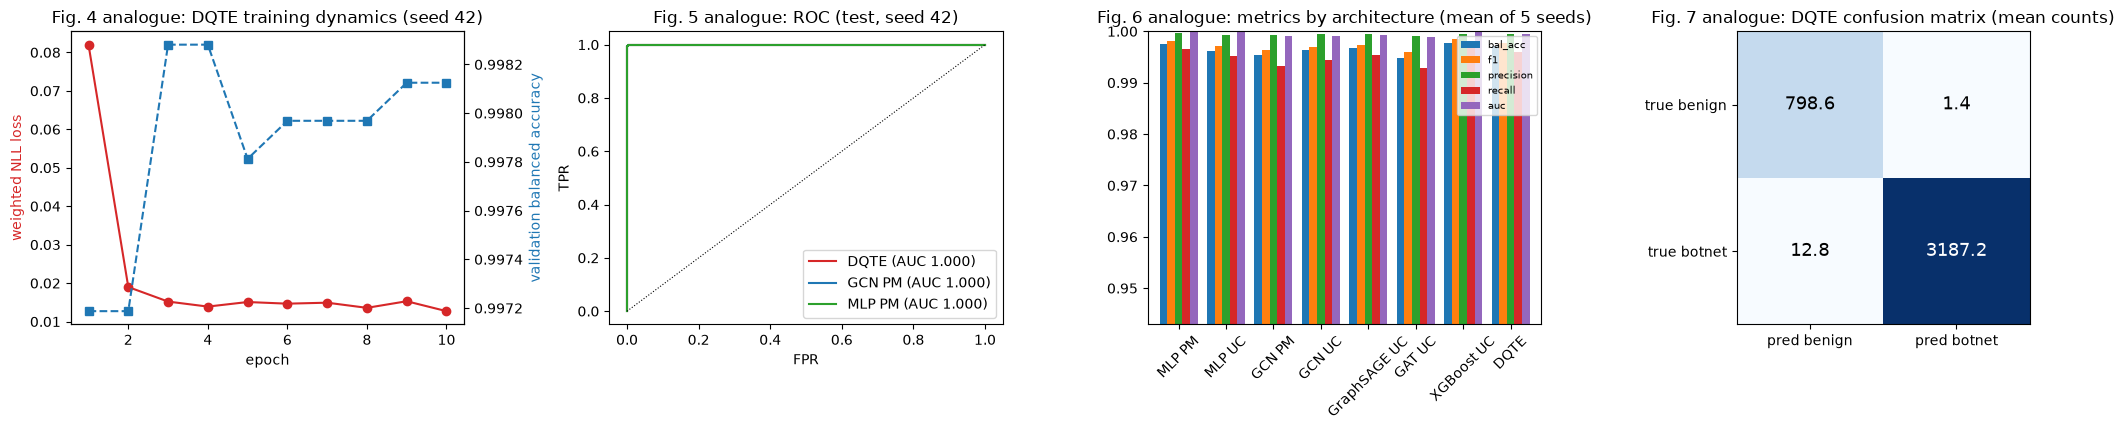

mean DQTE confusion matrix (TN FP / FN TP):
 [[7.9860e+02 1.4000e+00]
 [1.2800e+01 3.1872e+03]]


In [18]:
# ---- Fig. 4: training dynamics of DQTE (seed SEED)
h = ALL[SEED]["DQTE"]["hist"]
fig, ax = plt.subplots(1, 4, figsize=(21, 4.4))
ax[0].plot(h.epoch, h.loss, "o-", color="#d62728"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("weighted NLL loss", color="#d62728")
a2 = ax[0].twinx(); a2.plot(h.epoch, h.val_bal_acc, "s--", color="#1f77b4"); a2.set_ylabel("validation balanced accuracy", color="#1f77b4")
ax[0].set_title("Fig. 4 analogue: DQTE training dynamics (seed %d)" % SEED)

# ---- Fig. 5: ROC curves
for name, c in [("DQTE", "#d62728"), ("GCN PM", "#1f77b4"), ("MLP PM", "#2ca02c")]:
    fpr, tpr, _ = roc_curve(DATA["y"]["te"], ALL[SEED][name]["proba"])
    ax[1].plot(fpr, tpr, color=c, label=f"{name} (AUC {ALL[SEED][name]['auc']:.3f})")
ax[1].plot([0, 1], [0, 1], "k:", lw=0.8); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(); ax[1].set_title("Fig. 5 analogue: ROC (test, seed %d)" % SEED)

# ---- Fig. 6: benchmark bars
bars = ["MLP PM", "MLP UC", "GCN PM", "GCN UC", "GraphSAGE UC", "GAT UC", "XGBoost UC", "DQTE"]
mat = pd.DataFrame({k: [np.mean([ALL[s][m_][k] for s in SEEDS]) for m_ in bars] for k in ["bal_acc", "f1", "precision", "recall", "auc"]}, index=bars)
mat.plot.bar(ax=ax[2], ylim=(max(0.0, mat.values.min() - 0.05), 1.0), width=0.8); ax[2].tick_params(axis="x", rotation=45); ax[2].legend(fontsize=7)
ax[2].set_title("Fig. 6 analogue: metrics by architecture (mean of %d seeds)" % len(SEEDS))

# ---- Fig. 7: mean confusion matrix of DQTE
cm_mean = np.mean([ALL[s]["DQTE"]["cm"] for s in SEEDS], axis=0)
im = ax[3].imshow(cm_mean, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[3].text(j, i, f"{cm_mean[i, j]:.1f}", ha="center", va="center", color="white" if cm_mean[i, j] > cm_mean.max() / 2 else "black", fontsize=13)
ax[3].set_xticks([0, 1]); ax[3].set_xticklabels(["pred benign", "pred botnet"]); ax[3].set_yticks([0, 1]); ax[3].set_yticklabels(["true benign", "true botnet"])
ax[3].set_title("Fig. 7 analogue: DQTE confusion matrix (mean counts)")
plt.tight_layout(); plt.show()
print("mean DQTE confusion matrix (TN FP / FN TP):\n", np.round(cm_mean, 1))

### Sensitivity scenario B: every attack group counts as "botnet"

Mirai and DoS floods are almost trivially separable from benign traffic with these 39 features (see the table above), whereas the paper's
classical baselines sit at 0.81 to 0.91 balanced accuracy. As a sensitivity check we repeat the whole experiment with **all 33 attack types**
(Mirai, DoS, DDoS, Recon, spoofing, web attacks, brute force) as the positive class against benign, keeping every other setting. This harder task is
closer to the paper's baseline range and is reported next to scenario A in the verdict table.

Scenario B (all attacks vs benign): mean +/- std over 3 seeds, 20000 nodes per run


,Bal. Acc,F1 (attack),Recall,AUC
Model,,,,
DQTE,0.873 +/- 0.002,0.864 +/- 0.009,0.763 +/- 0.017,0.910 +/- 0.008
Topology + VQC only (no skip),0.862 +/- 0.009,0.867 +/- 0.003,0.774 +/- 0.010,0.909 +/- 0.006
No topology (raw PCA -> VQC),0.870 +/- 0.002,0.864 +/- 0.009,0.765 +/- 0.017,0.909 +/- 0.008
MLP PM,0.876 +/- 0.001,0.872 +/- 0.008,0.778 +/- 0.016,0.918 +/- 0.003
MLP UC,0.873 +/- 0.004,0.870 +/- 0.007,0.776 +/- 0.014,0.926 +/- 0.002
XGBoost UC,0.866 +/- 0.007,0.903 +/- 0.004,0.847 +/- 0.004,0.939 +/- 0.002
Topology + MLP (UC),0.872 +/- 0.003,0.866 +/- 0.004,0.768 +/- 0.009,0.925 +/- 0.002
Topology + RBF-SVM,0.868 +/- 0.001,0.850 +/- 0.001,0.739 +/- 0.002,0.909 +/- 0.004
RBF-SVM on raw PCA,0.871 +/- 0.001,0.854 +/- 0.002,0.745 +/- 0.003,0.910 +/- 0.004


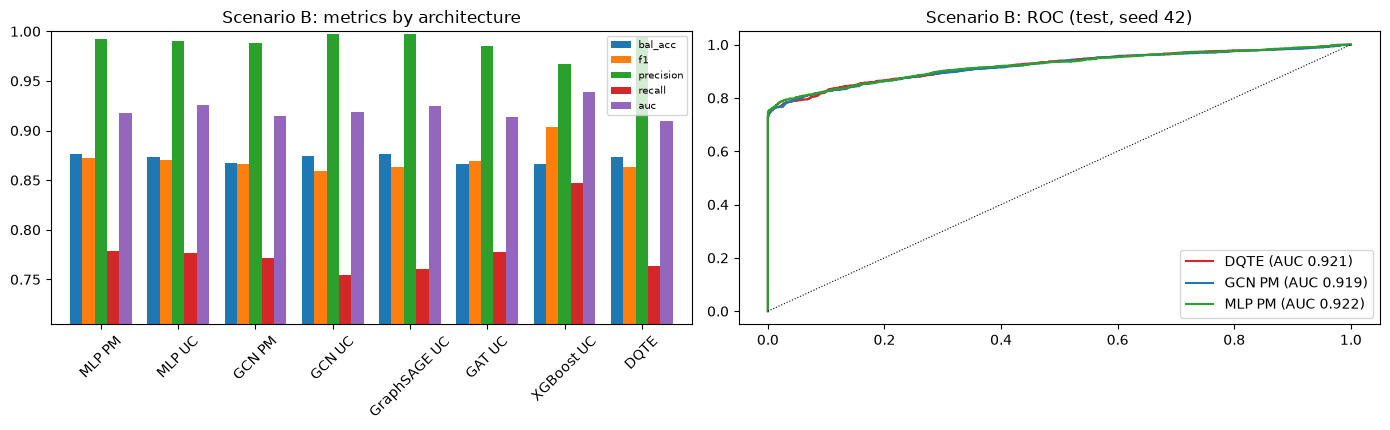

In [19]:
if ALL_B:
    rows = []
    for m_ in ALL_B[SEEDS_B[0]].keys():
        r = {"Model": m_}
        for k in ["bal_acc", "f1", "recall", "auc"]:
            v = np.array([ALL_B[s][m_][k] for s in SEEDS_B]); r[k] = f"{v.mean():.3f} +/- {v.std():.3f}"
        rows.append(r)
    summary_B = pd.DataFrame(rows).set_index("Model"); summary_B.columns = ["Bal. Acc", "F1 (attack)", "Recall", "AUC"]
    print(f"Scenario B (all attacks vs benign): mean +/- std over {len(SEEDS_B)} seeds, {N_NODES} nodes per run")
    display(summary_B)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
    mat_B = pd.DataFrame({k: [np.mean([ALL_B[s][m_][k] for s in SEEDS_B]) for m_ in bars] for k in ["bal_acc", "f1", "precision", "recall", "auc"]}, index=bars)
    mat_B.plot.bar(ax=ax[0], ylim=(max(0.0, mat_B.values.min() - 0.05), 1.0), width=0.8); ax[0].tick_params(axis="x", rotation=45); ax[0].legend(fontsize=7)
    ax[0].set_title("Scenario B: metrics by architecture")
    for name, c in [("DQTE", "#d62728"), ("GCN PM", "#1f77b4"), ("MLP PM", "#2ca02c")]:
        fpr, tpr, _ = roc_curve(DATA_B["y"]["te"], ALL_B[SEED][name]["proba"])
        ax[1].plot(fpr, tpr, color=c, label=f"{name} (AUC {ALL_B[SEED][name]['auc']:.3f})")
    ax[1].plot([0, 1], [0, 1], "k:", lw=0.8); ax[1].legend(); ax[1].set_title("Scenario B: ROC (test, seed %d)" % SEED)
    plt.tight_layout(); plt.show()

## 7. Gradient magnitude at initialisation (Table 1)

For each seed we build the model with and without the classical skip path, take one training mini-batch of 128 aggregated nodes, back-propagate the
weighted NLL and record the mean absolute gradient over the **24 circuit parameters** `theta`. The paper reports
0.0031 +/- 0.0008 (no skip) and 0.0412 +/- 0.0061 (skip) over 100 seeds. Which parameters and which loss scaling the paper used is not stated, so
this is a like-for-like *direction* check more than a number check.

In [20]:
def grad_at_init(skip, seed, D):
    m = HybridDQTE(skip=skip, seed=seed); m.train()
    g_ = np.random.default_rng(seed)
    b = g_.choice(len(D["Xp"]["tr"]), BATCH_SIZE, replace=False)
    xb_, yb_ = torch.as_tensor(D["Xp"]["tr"][b]), torch.as_tensor(D["y"]["tr"][b])
    F.nll_loss(m(xb_), yb_, weight=class_weights(D["y"]["tr"])).backward()
    return m.theta.grad.abs().mean().item()

gnoskip = np.array([grad_at_init(False, s, DATA) for s in range(GRAD_SEEDS)])
gskip = np.array([grad_at_init(True, s, DATA) for s in range(GRAD_SEEDS)])
tab1 = pd.DataFrame({"Architecture": ["VQC only (no skip)", "DQTE (with skip)"],
                     "this notebook mean |grad theta|": [f"{gnoskip.mean():.4f} +/- {gnoskip.std():.4f}", f"{gskip.mean():.4f} +/- {gskip.std():.4f}"],
                     "paper (Table 1)": ["0.0031 +/- 0.0008", "0.0412 +/- 0.0061"]}).set_index("Architecture")
print(f"over {GRAD_SEEDS} initialisation seeds")
tab1

over 100 initialisation seeds


,this notebook mean |grad theta|,paper (Table 1)
Architecture,,
VQC only (no skip),0.0892 +/- 0.0548,0.0031 +/- 0.0008
DQTE (with skip),0.0728 +/- 0.0500,0.0412 +/- 0.0061


## 8. Inference latency (Table 5) and the ablation table (Table 4)

In [21]:
# latency of a forward pass over a batch of 128 nodes (eval mode, averaged over 100 batches)
mdl = ALL[SEED]["DQTE"]["model"]; mdl.eval()
xb_ = torch.as_tensor(DATA["Xp"]["te"][:BATCH_SIZE])
with torch.no_grad():
    for _ in range(5): mdl(xb_)
    t0 = time.time()
    for _ in range(100): mdl(xb_)
lat_torch = 1000 * (time.time() - t0) / 100
print(f"DQTE inference latency, batch of {BATCH_SIZE}: {lat_torch:.2f} ms (torch state-vector, CPU) | paper Table 5: 4.1 ms (lightning.qubit, Xeon)")
# same measurement with the PennyLane lightning.qubit QNode as the quantum core (forward only, 10 batches)
with torch.no_grad():
    th = mdl.theta.detach().double()
    qnode(xb_.double(), th)
    t0 = time.time()
    for _ in range(3): qnode(xb_.double(), th)
lat_pl = 1000 * (time.time() - t0) / 3
print(f"quantum core alone on lightning.qubit (forward, batch {BATCH_SIZE}): {lat_pl:.1f} ms vs torch state-vector {lat_torch:.2f} ms for the whole model")

abl = ["No topology (raw PCA -> VQC)", "Topology + RBF-SVM", "Topology + MLP (UC)", "Topology + VQC only (no skip)", "DQTE"]
paper_t4 = {"No topology (raw PCA -> VQC)": (0.841, 0.903), "Topology + RBF-SVM": (0.921, 0.962), "Topology + MLP (UC)": (0.918, 0.959),
            "Topology + VQC only (no skip)": (0.907, 0.948), "DQTE": (0.953, 0.985)}
t4 = pd.DataFrame([{"Variant": a,
                    "Bal. Acc (notebook)": f"{np.mean([ALL[s][a]['bal_acc'] for s in SEEDS]):.3f} +/- {np.std([ALL[s][a]['bal_acc'] for s in SEEDS]):.3f}",
                    "Bal. Acc (paper)": paper_t4[a][0],
                    "AUC (notebook)": f"{np.mean([ALL[s][a]['auc'] for s in SEEDS]):.3f} +/- {np.std([ALL[s][a]['auc'] for s in SEEDS]):.3f}",
                    "AUC (paper)": paper_t4[a][1]} for a in abl]).set_index("Variant")
ba_d = np.array([ALL[s]["DQTE"]["bal_acc"] for s in SEEDS]); ba_s = np.array([ALL[s]["Topology + RBF-SVM"]["bal_acc"] for s in SEEDS])
if len(SEEDS) > 2 and np.any(ba_d != ba_s):
    tt = stats.ttest_rel(ba_d, ba_s)
    print(f"paired t-test DQTE vs topology + RBF-SVM over {len(SEEDS)} seeds: mean difference {np.mean(ba_d - ba_s):+.4f}, p = {tt.pvalue:.3g}")
t4

DQTE inference latency, batch of 128: 56.26 ms (torch state-vector, CPU) | paper Table 5: 4.1 ms (lightning.qubit, Xeon)


quantum core alone on lightning.qubit (forward, batch 128): 1349.8 ms vs torch state-vector 56.26 ms for the whole model
paired t-test DQTE vs topology + RBF-SVM over 5 seeds: mean difference +0.0012, p = 0.015


,Bal. Acc (notebook),Bal. Acc (paper),AUC (notebook),AUC (paper)
Variant,,,,
No topology (raw PCA -> VQC),0.991 +/- 0.009,0.841,1.000 +/- 0.000,0.903
Topology + RBF-SVM,0.996 +/- 0.001,0.921,1.000 +/- 0.000,0.962
Topology + MLP (UC),0.996 +/- 0.001,0.918,0.999 +/- 0.001,0.959
Topology + VQC only (no skip),0.997 +/- 0.001,0.907,0.999 +/- 0.001,0.948
DQTE,0.997 +/- 0.000,0.953,0.999 +/- 0.000,0.985


## 9. Side by side with the paper: one verdict per claim

Rule (as in this series): **reproduced** if the notebook value is within 0.02 of the paper's (balanced accuracy, F1, recall, AUC, FPR, FNR),
**exceeded** if it is higher by more than 0.02, **not reached** if lower by more than 0.02; **cannot be checked** when this CPU notebook has no way to measure the quantity.
For qualitative claims (orderings) the verdict is *reproduced / not reproduced*.

In [22]:
def mean_of(model, key, B=False):
    R_, S_ = (ALL_B, SEEDS_B) if B else (ALL, SEEDS)
    return float(np.mean([R_[s][model][key] for s in S_]))

def verdict(paper, ours, tol=0.02, higher_is_better=True):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    return ("exceeded" if (d > 0) == higher_is_better else "not reached")

claims = []
def add(claim, paper, ours, tol=0.02, hib=True, note="", model=None, key=None):
    # ours = scenario A (Mirai + DoS); if model/key are given, scenario B (all attacks) is evaluated too
    row = dict(Claim=claim, Paper=paper, Notebook_A=round(ours, 4), Gap_A=round(ours - paper, 4), Verdict_A=verdict(paper, ours, tol, hib))
    if model is not None and ALL_B:
        b = mean_of(model, key, B=True)
        row.update(Notebook_B=round(b, 4), Gap_B=round(b - paper, 4), Verdict_B=verdict(paper, b, tol, hib))
    row["Note"] = note
    claims.append(row)

t3 = {"MLP PM": (0.812, 0.809, 0.801, 0.884), "MLP UC": (0.856, 0.853, 0.849, 0.913), "GCN PM": (0.871, 0.868, 0.864, 0.941),
      "GCN UC": (0.889, 0.887, 0.883, 0.953), "GraphSAGE UC": (0.901, 0.899, 0.895, 0.961), "GAT UC": (0.908, 0.906, 0.901, 0.965),
      "XGBoost UC": (0.893, 0.891, 0.888, 0.958), "DQTE": (0.953, 0.951, 0.948, 0.985)}
for m_, (ba, f1_, rc, au) in t3.items():
    add(f"Table 3 {m_}: balanced accuracy", ba, mean_of(m_, "bal_acc"), model=m_, key="bal_acc")
add("Table 3 DQTE: F1", 0.951, mean_of("DQTE", "f1"), model="DQTE", key="f1")
add("Table 3 DQTE: recall", 0.948, mean_of("DQTE", "recall"), model="DQTE", key="recall")
add("Table 3 DQTE: AUC", 0.985, mean_of("DQTE", "auc"), model="DQTE", key="auc")
add("Fig. 5 GCN PM AUC", 0.941, mean_of("GCN PM", "auc"), model="GCN PM", key="auc")
add("Fig. 5 MLP PM AUC", 0.884, mean_of("MLP PM", "auc"), model="MLP PM", key="auc")
for a in abl[:-1]:
    add(f"Table 4 {a}: balanced accuracy", paper_t4[a][0], mean_of(a, "bal_acc"), model=a, key="bal_acc")
add("Fig. 7 DQTE false-positive rate", 0.056, mean_of("DQTE", "fpr"), hib=False, note="lower is better", model="DQTE", key="fpr")
add("Fig. 7 DQTE false-negative rate", 0.0297, mean_of("DQTE", "fnr"), hib=False, note="lower is better", model="DQTE", key="fnr")
add("Table 1 mean |grad| without skip", 0.0031, float(gnoskip.mean()), tol=0.002, note="absolute tolerance 0.002")
add("Table 1 mean |grad| with skip", 0.0412, float(gskip.mean()), tol=0.01, note="absolute tolerance 0.01")
add("Table 2 trainable parameters of DQTE", 168, n_params(m_demo), tol=10, note="paper's own formula inconsistent with BasicEntanglerLayers; tolerance 10")
add("Table 5 inference latency per 128 nodes (ms)", 4.1, lat_torch, tol=3.0, hib=False, note="different simulator and CPU; tolerance 3 ms")
cmp_df = pd.DataFrame(claims)

# qualitative claims
def qual_claims(B):
    mo = lambda m_: mean_of(m_, "bal_acc", B)
    best_classical = max(mo(m_) for m_ in ["MLP PM", "MLP UC", "GCN PM", "GCN UC", "GraphSAGE UC", "GAT UC", "XGBoost UC"])
    return [
        ("DQTE has the highest balanced accuracy of all Table-3 models", mo("DQTE") > best_classical),
        ("DQTE > Topology + RBF-SVM (Table 4)", mo("DQTE") > mo("Topology + RBF-SVM")),
        ("DQTE > Topology + MLP (UC) (Table 4)", mo("DQTE") > mo("Topology + MLP (UC)")),
        ("DQTE > Topology + VQC only, i.e. the skip path helps (Table 4)", mo("DQTE") > mo("Topology + VQC only (no skip)")),
        ("Topology helps: DQTE > the same hybrid on raw PCA (paper: about +11 to 12 points)", mo("DQTE") > mo("No topology (raw PCA -> VQC)")),
        ("Graph models beat the topology-free MLP (PM) (Sec. 4.4)", mo("GCN PM") > mo("MLP PM")),
    ]
qA, qB = qual_claims(False), (qual_claims(True) if ALL_B else None)
rows_q = []
for i, (c, ok) in enumerate(qA):
    r = dict(Claim=c, Verdict_A="reproduced" if ok else "not reproduced")
    if qB: r["Verdict_B"] = "reproduced" if qB[i][1] else "not reproduced"
    rows_q.append(r)
rows_q.append(dict(Claim="Skip path enlarges initial gradients (Table 1), scenario A data", Verdict_A="reproduced" if gskip.mean() > gnoskip.mean() else "not reproduced"))
rows_q.append(dict(Claim="Loss decreases over the 10 epochs (Fig. 4)", Verdict_A="reproduced" if h.loss.iloc[-1] < h.loss.iloc[0] else "not reproduced"))
qdf = pd.DataFrame(rows_q).fillna("")
nocheck = pd.DataFrame([dict(Claim=c, Verdict="cannot be checked", Note=n) for c, n in [
    ("100 runs per model", "this notebook uses %d seeds" % len(SEEDS)),
    ("About 4x training speed-up from pre-computed aggregation (Sec. 4.5)", "dynamic message passing inside the quantum loop is not implemented in the paper's text; not measured"),
    ("Table 5 FLOPs and memory", "analytic estimates of the authors, not measured here"),
    ("Error-mode analysis (FPs are streaming-like benign nodes)", "no application-level labels in the public table"),
    ("Quantum advantage as a statement about Hilbert-space expressivity", "a classical simulator cannot test it; see critical reading")]])
pd.set_option("display.width", 200, "display.max_colwidth", 80)
print("Quantitative claims"); display(cmp_df.fillna(""))
print("Qualitative claims"); display(qdf)
print("Not checkable here"); display(nocheck)
print("\nverdict counts A:", cmp_df.Verdict_A.value_counts().to_dict(), "| qualitative A:", qdf.Verdict_A.value_counts().to_dict())
if ALL_B:
    print("verdict counts B:", cmp_df.Verdict_B.value_counts().to_dict(), "| qualitative B:", qdf.Verdict_B[qdf.Verdict_B != ""].value_counts().to_dict())

Quantitative claims


,Claim,Paper,Notebook_A,Gap_A,Verdict_A,Notebook_B,Gap_B,Verdict_B,Note
0,Table 3 MLP PM: balanced accuracy,0.8120,0.9975,0.1855,exceeded,0.8764,0.0644,exceeded,
1,Table 3 MLP UC: balanced accuracy,0.8560,0.9962,0.1402,exceeded,0.873,0.017,reproduced,
2,Table 3 GCN PM: balanced accuracy,0.8710,0.9954,0.1244,exceeded,0.8668,-0.0042,reproduced,
3,Table 3 GCN UC: balanced accuracy,0.8890,0.9963,0.1073,exceeded,0.8739,-0.0151,reproduced,
4,Table 3 GraphSAGE UC: balanced accuracy,0.9010,0.9968,0.0958,exceeded,0.8768,-0.0242,not reached,
5,Table 3 GAT UC: balanced accuracy,0.9080,0.9948,0.0868,exceeded,0.8659,-0.0421,not reached,
6,Table 3 XGBoost UC: balanced accuracy,0.8930,0.9978,0.1048,exceeded,0.866,-0.027,not reached,
7,Table 3 DQTE: balanced accuracy,0.9530,0.9971,0.0441,exceeded,0.8733,-0.0797,not reached,
8,Table 3 DQTE: F1,0.9510,0.9978,0.0468,exceeded,0.8636,-0.0874,not reached,
9,Table 3 DQTE: recall,0.9480,0.9960,0.0480,exceeded,0.7632,-0.1848,not reached,


Qualitative claims


,Claim,Verdict_A,Verdict_B
0,DQTE has the highest balanced accuracy of all Table-3 models,not reproduced,not reproduced
1,DQTE > Topology + RBF-SVM (Table 4),reproduced,reproduced
2,DQTE > Topology + MLP (UC) (Table 4),reproduced,reproduced
3,"DQTE > Topology + VQC only, i.e. the skip path helps (Table 4)",reproduced,reproduced
4,Topology helps: DQTE > the same hybrid on raw PCA (paper: about +11 to 12 po...,reproduced,reproduced
5,Graph models beat the topology-free MLP (PM) (Sec. 4.4),not reproduced,not reproduced
6,"Skip path enlarges initial gradients (Table 1), scenario A data",not reproduced,
7,Loss decreases over the 10 epochs (Fig. 4),reproduced,


Not checkable here


,Claim,Verdict,Note
0,100 runs per model,cannot be checked,this notebook uses 5 seeds
1,About 4x training speed-up from pre-computed aggregation (Sec. 4.5),cannot be checked,dynamic message passing inside the quantum loop is not implemented in the pa...
2,Table 5 FLOPs and memory,cannot be checked,"analytic estimates of the authors, not measured here"
3,Error-mode analysis (FPs are streaming-like benign nodes),cannot be checked,no application-level labels in the public table
4,Quantum advantage as a statement about Hilbert-space expressivity,cannot be checked,a classical simulator cannot test it; see critical reading



verdict counts A: {'exceeded': 20, 'reproduced': 2, 'not reached': 1} | qualitative A: {'reproduced': 5, 'not reproduced': 3}
verdict counts B: {'not reached': 12, 'exceeded': 4, 'reproduced': 3} | qualitative B: {'reproduced': 4, 'not reproduced': 2}


## 10. Reading the paper critically

* **The graph is not a network graph.** Edges are k-NN links in the 8-D PCA space, so the "topological" aggregation is a
  neighbourhood *mean in feature space* (with `D_hat = (k+1) I`, `L_hat = A_hat / (k+1)` exactly). It is a smoothing/denoising step, a
  kind of k-NN feature averaging, and says nothing about hosts or communication patterns; the paper is upfront about this. The edge-homophily numbers
  printed in the exploration section show how much label information the smoothing can exploit: when most k-NN edges join nodes of the same class, a
  neighbourhood mean makes classes easier to separate for *any* classifier, quantum or not (compare "Topology + RBF-SVM" and "Topology + RandomForest" with
  their topology-free versions).
* **Fair quantum-vs-classical comparison.** Table 4 gives the quantum model a mean-aggregated input, a linear skip, BatchNorm and a head, so the final
  classifier is a hybrid of a linear model and 24 circuit parameters. A classical model with the same inputs and a comparable parameter count
  (here: RBF-SVM and Random Forest on `X'`, MLPs) is the relevant control. The paper's own "VQC only (no skip)" result is below its RBF-SVM
  and MLP rows, so the benefit seen for DQTE comes with the classical branch.
* **Internal inconsistencies.** The text says 4 : 1 botnet : benign while the confusion matrix in Fig. 7 implies about 1 : 1; Table 2 counts 72 circuit
  parameters although `BasicEntanglerLayers` with 3 layers on 8 qubits has 24; the paired t-test statement has an unfilled "+X %"; Table 3 reports 100 runs but
  gives no information on whether the dataset sample, split or only the initialisation changes.
* **Idealised hardware.** Everything is exact state-vector simulation. Nothing was run with shot noise or hardware noise, and 8 qubits are trivially simulable
  classically (256 amplitudes), so the "high-dimensional Hilbert space" argument does not by itself imply an advantage.
* **Data.** Mirai and DoS flows in CIC-IoT-2023 are volumetric and highly regular; benign-vs-flood is an easy task even for plain tabular models (see the Random Forest rows),
  so absolute numbers say little about "stealthy P2P botnets". Choices of which labels count as botnet, the number of nodes and k are not given in the paper and change the numbers.
  The two scenarios bracket the paper: with Mirai + DoS (scenario A) *every* model, including the paper's weakest MLP, is far above the paper's baselines; with all attack types
  (scenario B) the classical baselines fall into the paper's 0.81 to 0.91 range, but then DQTE does not reach the paper's 0.953 either.
* **What this reproduction found.** In neither scenario did we find the ordering the paper reports (DQTE clearly above GCN, GraphSAGE, GAT, XGBoost, RBF-SVM and MLP
  fed with the same aggregated features). The k-NN aggregation did not help the classical models on raw PCA features either (compare the "Topology +" rows with the raw-PCA rows).
  A plausible reason is that a k-NN mean in the same PCA space the classifier already sees adds little information, and that smoothing hurts the minority/rare attack types
  (scenario B). The paper's Table 4 gap of about 11 points between "no topology" and DQTE is not visible here. Whether the authors' graph carried extra information (for example
  because the neighbours were built from different features than those fed to the VQC, or across the train/test boundary) cannot be decided from the text.
* **Gradient table.** Mean |gradient| at initialisation depends on the loss scaling, the batch, and which parameters are averaged; it is not a barren-plateau analysis (the authors say so).
  Here the 24 circuit angles are initialised uniformly in [0, 2 pi] and, on 8 qubits, gradients are not small with or without the skip path, so the barren-plateau argument does not
  bind at this size.
* **Statistics.** The paper reports means over 100 runs with standard deviations of 0.004 to 0.009; with a handful of seeds our standard deviations are of the same order or larger, and
  many of the differences between the strong models are within one standard deviation. Treat sub-point differences as ties.

## 11. Exercises

1. Change `K_NEIGHBOURS` to 3, 5, 20, 50. How do edge homophily, the "Topology + RBF-SVM" score and DQTE change?
2. Build the graph **across** splits (one transductive graph over train+validation+test nodes) and compare. Why does this raise a leakage question even though no labels are used?
3. Replace `BasicEntanglerLayers` by `StronglyEntanglingLayers` (3 rotations per qubit, 72 circuit parameters, which is what Table 2's formula actually counts). Does it change the result? Use the equivalence cell as a template to validate your simulator.
4. Add noise (`default.mixed` with a depolarising channel after every CNOT) to the PennyLane QNode, evaluate the trained DQTE on the test set with it, and plot balanced accuracy vs the noise rate.
5. Add the other attack groups (DDoS, Recon, Spoofing) as additional botnet or non-botnet classes and test whether DQTE still beats the RBF-SVM on `X'`. Which classes are the hardest and why?